In [1]:
import geopandas as gpd
import pandas as pd
from folium import (
    LayerControl,
    Element,
    TileLayer,
)
import plotly.express as px
from os import path, makedirs


from core.geo import areal_weighted_interpolation
from core.urbanismo import prepare_tracts, prepare_risk_area

# Carregando os dados extraídos no notebook anterior

Neste notebook, vamos utilizar os dados extraídos e salvos pelo notebook [urbanismo/urbanismo - extração.ipynb](https://github.com/ObservatorioPoliticasTCM/dados-painel/blob/main/notebooks/urbanismo/urbanismo%20-%20extra%C3%A7%C3%A3o.ipynb).

In [2]:
cache_dir = output_dir = path.join('data', 'cache', 'urbanismo')

In [3]:
df_hid = gpd.read_file(path.join(cache_dir, 'risco_hidrologico_original.gpkg'))
df_hid


,id,cd_identificador_risco_hidrologico,nm_area_risco_hidrologico,tx_grau_risco_hidrologico,sg_area_risco_hidrologico,sg_setor_risco_hidrologico,tx_tipo_processo,dt_vistoria,qt_moradia,nm_subprefeitura,nm_bacia_hidrografica,geometry
0,risco_hidrologico.1,1,BARTOLOMEU FEIO,R2,HPI-01,HPI-01-01 (R2),ALAGAMENTO,2021-08-24,44,PINHEIROS,CORREGO AGUA ESPRAIADA,"POLYGON ((327424.845 7387319.281, 327417.205 7..."
1,risco_hidrologico.2,2,MAURO,R2,HVM-01,HVM-01-01 (R2),ENCHENTE/INUNDACAO,2022-02-01,15,VILA MARIANA,CORREGO UBERABA,"POLYGON ((332457.88 7386410.997, 332469.137 73..."
2,risco_hidrologico.3,3,MAURO,R3,HVM-01,HVM-01-02 (R3),ENCHENTE/INUNDACAO,2022-02-01,57,VILA MARIANA,CORREGO UBERABA,"POLYGON ((332476.102 7386409.838, 332469.228 7..."
3,risco_hidrologico.4,4,NEIDE APARECIDA SOLITO,R2,HVM-02,HVM-02-01 (R2),ALAGAMENTO,2022-02-01,12,VILA MARIANA,CORREGO DO SAPATEIRO,"POLYGON ((331840.472 7389826.482, 331845.268 7..."
4,risco_hidrologico.5,5,ESTEVAM HERNANDES,R2,HVM-03,HVM-03-01 (R2),ENCHENTE/INUNDACAO,2022-02-01,8,VILA MARIANA,CORREGO ACLIMACAO,"POLYGON ((333351.063 7391149.539, 333377.019 7..."
...,...,...,...,...,...,...,...,...,...,...,...,...
788,risco_hidrologico.789,789,ELISEU TEIXEIRA LEITE - PJ,R3,HPJ-12,HPJ-12-03 (R3),ALAGAMENTO/ENCHENTE/INUNDACAO,2022-05-12,40,PIRITUBA-JARAGUA,CORREGO CABUCU DE BAIXO,"POLYGON ((325473.75 7405366.642, 325472.025 74..."
789,risco_hidrologico.790,790,JARDIM RINCAO II,R3,HPJ-05,HPJ-05-02 (R3),ENCHENTE/INUNDACAO,2025-06-11,30,PIRITUBA-JARAGUA,RIBEIRAO DOS PERUS,"POLYGON ((323562.04 7406876.66, 323551.922 740..."
790,risco_hidrologico.791,791,JARDIM RINCAO II,R2,HPJ-05,HPJ-05-01 (R2),ENCHENTE/INUNDACAO/ALAGAMENTO,2025-06-11,450,PIRITUBA-JARAGUA,RIBEIRAO DOS PERUS,"POLYGON ((323684.858 7407010.34, 323684.797 74..."
791,risco_hidrologico.792,792,TOME DE ALMEIDA E OLIVEIRA,R3,HPJ-19,HPJ-19-01 (R3),ENCHENTE/INUNDACAO/ALAGAMENTO,2025-06-11,40,PIRITUBA-JARAGUA,RIBEIRAO VERDE - REGIAO NORTE,"POLYGON ((325248.523 7403385.87, 325270.466 74..."


In [4]:
df_geo = gpd.read_file(path.join(cache_dir, 'risco_geologico_original.gpkg'))
df_geo


,id,cd_identificador,nm_area_risco,tx_grau_de_risco_geologico,sg_area_risco,sg_setor_risco,tx_tipo_processo_geologico,cd_tipo_processo_geologico,cd_grau_risco_geologico,dt_atualizacao,dt_vistoria,sg_fonte_original,qt_moradia,geometry
0,area_risco_geologico.1,1,AVENIDA SANTO AFONSO I,AREA ENCERRADA,AD-01,AREA ENCERRADA,ESCORREGAMENTO,2,99,2026-10-06 03:00:00+00:00,2022-02-02,18,0,"POLYGON ((332306.817 7380115.28, 332246.187 73..."
1,area_risco_geologico.2,2,RUA SAO BENTO XV,r3,AD-04,AD-04-03 (R3),SOLAPAMENTO,4,3,2026-10-06 03:00:00+00:00,2026-04-01,18,50,"POLYGON ((332324.725 7378882.633, 332309.159 7..."
2,area_risco_geologico.3,3,RUA SAO BENTO XV,r3,AD-04,AD-04-01 (R3),SOLAPAMENTO,4,3,2026-10-06 03:00:00+00:00,2026-04-01,18,30,"POLYGON ((332060.389 7379330.535, 332080.779 7..."
3,area_risco_geologico.4,4,RUA SAO BENTO XV,r1,AD-04,AD-04-02 (R1),SOLAPAMENTO,4,1,2026-10-06 03:00:00+00:00,2026-04-01,18,200,"POLYGON ((332309.159 7378872.908, 332286.448 7..."
4,area_risco_geologico.5,5,RUA SAO BENTO XV,r1,AD-04,AD-04-04 (R1),SOLAPAMENTO,4,1,2026-10-06 03:00:00+00:00,2026-04-01,18,250,"POLYGON ((332324.725 7378882.633, 332310.909 7..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1396,area_risco_geologico.1397,1397,MANGUE,r2,VP-02,VP-02-02 (R2),SOLAPAMENTO,4,2,2026-10-06 03:00:00+00:00,2025-10-15,18,50,"POLYGON ((343811.294 7387761.125, 343817.849 7..."
1397,area_risco_geologico.1398,1398,MANGUE,r2,VP-02,VP-02-03 (R2),SOLAPAMENTO,4,2,2026-10-06 03:00:00+00:00,2025-10-15,18,12,"POLYGON ((343678.819 7387672.919, 343709.158 7..."
1398,area_risco_geologico.1399,1399,MANGUE,r1,VP-02,VP-02-04 (R1),SOLAPAMENTO,4,1,2026-10-06 03:00:00+00:00,2025-10-15,18,40,"POLYGON ((343958.827 7387695.264, 343950.855 7..."
1399,area_risco_geologico.1400,1400,ANDRE DA CUNHA FONSECA,r2,VP-03,VP-03-01 (R2),SOLAPAMENTO,4,2,2026-10-06 03:00:00+00:00,2023-10-16,18,150,"POLYGON ((344340.465 7388247.202, 344344.264 7..."


In [5]:
df_censo = gpd.read_file(path.join(cache_dir, 'setores_censitarios_original.gpkg'))
df_censo

,CD_SETOR,SITUACAO,CD_SIT,CD_TIPO,AREA_KM2,CD_REGIAO,NM_REGIAO,CD_UF,NM_UF,CD_MUN,...,CD_CONCURB,NM_CONCURB,v0001,v0002,v0003,v0004,v0005,v0006,v0007,geometry
0,355030801000001,Urbana,1,0,0.071797,3,Sudeste,35,São Paulo,3550308,...,3550308,São Paulo/SP,682,329,329,0,2.4,0.0381,289,"POLYGON ((339819.408 7392592.742, 339756.894 7..."
1,355030801000002,Urbana,1,0,0.071902,3,Sudeste,35,São Paulo,3550308,...,3550308,São Paulo/SP,1374,1011,1011,0,2.3,0.0150,599,"POLYGON ((339965.621 7393034.24, 339986.558 73..."
2,355030801000003,Urbana,1,0,0.055681,3,Sudeste,35,São Paulo,3550308,...,3550308,São Paulo/SP,557,239,238,1,2.7,0.0927,205,"POLYGON ((340157.888 7392942.284, 340144.598 7..."
3,355030801000004,Urbana,1,0,0.064905,3,Sudeste,35,São Paulo,3550308,...,3550308,São Paulo/SP,526,245,245,0,2.4,0.0136,221,"POLYGON ((339898.255 7392661.983, 339912.255 7..."
4,355030801000005,Urbana,1,0,0.086822,3,Sudeste,35,São Paulo,3550308,...,3550308,São Paulo/SP,579,258,258,0,2.6,0.0905,221,"POLYGON ((339650.83 7392494.454, 339716.68 739..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27296,355030896000345,Urbana,2,4,0.072194,3,Sudeste,35,São Paulo,3550308,...,3550308,São Paulo/SP,0,0,0,0,0.0,0.0000,0,"POLYGON ((354324.092 7397531.959, 354328.672 7..."
27297,355030896000346,Urbana,1,0,0.030599,3,Sudeste,35,São Paulo,3550308,...,3550308,São Paulo/SP,525,186,186,0,3.1,0.2754,167,"POLYGON ((354539.073 7397602.478, 354530.75 73..."
27298,355030896000347,Urbana,1,1,0.021137,3,Sudeste,35,São Paulo,3550308,...,3550308,São Paulo/SP,339,127,127,0,2.9,0.0690,116,"POLYGON ((358000.653 7397497.126, 357886.748 7..."
27299,355030896000348,Urbana,2,4,0.031962,3,Sudeste,35,São Paulo,3550308,...,3550308,São Paulo/SP,0,0,0,0,0.0,0.0000,0,"POLYGON ((357912.856 7397411.072, 357783.427 7..."


In [6]:
df_censo.crs

<Projected CRS: EPSG:31983>
Name: SIRGAS 2000 / UTM zone 23S
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Brazil - between 48°W and 42°W, northern and southern hemispheres, onshore and offshore.
- bounds: (-48.0, -33.5, -42.0, 5.13)
Coordinate Operation:
- name: UTM zone 23S
- method: Transverse Mercator
Datum: Sistema de Referencia Geocentrico para las AmericaS 2000
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [7]:
df_veg = gpd.read_file(path.join(cache_dir, 'cobertura_vegetal_original.gpkg'))
df_veg

,id,cd_identificador_vegetacao,cd_identificador_original_vegetacao,cd_controle_vetor,tx_datum,cd_coordenada_x,cd_coordenada_y,cd_categoria_vegetacao,cd_subcategoria_vegetacao,cd_subcategoria_complementar_vegetacao,tx_descricao_categoria_subcategoria,qt_area_vegetacao,qt_perimetro_vegetacao,qt_altura_media_vegetacao,qt_desvio_altura_vegetacao,tx_data_voo,tx_entrega,tx_lote,tx_lote_versao,geometry
0,cobertura_vegetal.1,1,1,6007,"SIRGAS 2000,4 - 23S",332758.39,7397643.24,13,0.0,0,"Média a alta cobertura arbórea, arbóreo-arbust...",3.486176e+02,120.94237,0.00000,0.00000,2017,04_2018,001,V2,"POLYGON ((332753.553 7397632.176, 332753.507 7..."
1,cobertura_vegetal.2,2,2,879,"SIRGAS 2000,4 - 23S",333723.72,7397905.09,13,0.0,0,"Média a alta cobertura arbórea, arbóreo-arbust...",5.719768e+03,1021.64520,0.00000,0.00000,2017,04_2018,001,V2,"POLYGON ((333701.991 7397891.395, 333704.261 7..."
2,cobertura_vegetal.3,3,3,92439,"SIRGAS 2000,4 - 23S",329698.03,7397184.05,14,0.0,0,Vegetação herbáceo-arbustiva,1.626148e+02,76.32568,0.00000,0.00000,2017,04_2018,001,V2,"POLYGON ((329681.866 7397188.032, 329707.705 7..."
3,cobertura_vegetal.4,4,4,92440,"SIRGAS 2000,4 - 23S",331187.14,7398350.32,14,0.0,0,Vegetação herbáceo-arbustiva,1.322249e+02,153.70879,0.00000,0.00000,2017,04_2018,001,V2,"POLYGON ((331152.165 7398355.317, 331226.746 7..."
4,cobertura_vegetal.5,5,5,92441,"SIRGAS 2000,4 - 23S",331186.11,7398338.59,14,0.0,0,Vegetação herbáceo-arbustiva,1.153769e+02,164.42277,0.00000,0.00000,2017,04_2018,001,V2,"POLYGON ((331150.944 7398344.021, 331231.026 7..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
272112,cobertura_vegetal.800076,800076,77,73,"SIRGAS 2000,4 - 23S",319624.77,7403025.10,2,0.0,0,Floresta ombrófila densa secundária em estágio...,2.557110e+06,34658.88096,13.46036,4.54563,2017,11_2019,015,V1,"POLYGON ((319769.846 7402729.901, 319769.089 7..."
272113,cobertura_vegetal.800077,800077,78,79,"SIRGAS 2000,4 - 23S",319624.77,7403025.10,3,0.0,0,Floresta ombrófila densa secundária em estágio...,9.379589e+04,4692.04033,9.62801,3.32908,2017,11_2019,015,V1,"POLYGON ((319309.503 7402847.334, 319322.51 74..."
272114,cobertura_vegetal.800078,800078,79,80,"SIRGAS 2000,4 - 23S",320357.64,7403432.43,3,0.0,0,Floresta ombrófila densa secundária em estágio...,7.919025e+04,2564.88564,10.25940,3.61652,2017,11_2019,015,V1,"POLYGON ((320348.313 7403132.752, 320346.032 7..."
272115,cobertura_vegetal.800079,800079,80,81,"SIRGAS 2000,4 - 23S",318676.76,7404717.05,11,0.0,0,"Média a alta cobertura arbórea, arbóreo-arbust...",1.177771e+03,510.13255,0.00000,0.00000,2017,11_2019,015,V1,"POLYGON ((318681.69 7404623.014, 318678.469 74..."


In [8]:
df_quadras = gpd.read_file(path.join(cache_dir, 'quadras_viarias_original.gpkg'))
df_quadras

,id,cd_identificador_quadra_viaria_editada,cd_identificador_quadra_viaria_editada_original,tx_tipo_quadra_viaria,tx_escala,tx_ano_referencia,qt_area_metro,sg_fonte_original,geometry
0,quadra_viaria_editada.fid-2998239a_1a12e3e662d...,1,1,Quadra,1:1.000,2020,7646,GEOINFO,"POLYGON ((338344.482 7407584.661, 338344.543 7..."
1,quadra_viaria_editada.fid-2998239a_1a12e3e662d...,2,2,Praca_Canteiro,1:1.000,2004,12,GEOINFO,"POLYGON ((327186.316 7377154.793, 327188.886 7..."
2,quadra_viaria_editada.fid-2998239a_1a12e3e662d...,3,3,Praca_Canteiro,1:1.000,2004,7,GEOINFO,"POLYGON ((324545.386 7402131.104, 324544.17 74..."
3,quadra_viaria_editada.fid-2998239a_1a12e3e662d...,4,4,Praca_Canteiro,1:1.000,2004,109,GEOINFO,"POLYGON ((326273.589 7399282.971, 326273.013 7..."
4,quadra_viaria_editada.fid-2998239a_1a12e3e662d...,5,5,Praca_Canteiro,1:1.000,2004,13,GEOINFO,"POLYGON ((322149.447 7392535.031, 322154.771 7..."
...,...,...,...,...,...,...,...,...,...
65715,quadra_viaria_editada.fid-2998239a_1a12e454165...,65716,67653,Quadra,1:1.000,2004,40175,GEOINFO,"POLYGON ((321906.421 7381423.552, 321906.979 7..."
65716,quadra_viaria_editada.fid-2998239a_1a12e454165...,65717,67657,Praca_Canteiro,1:1.000,2020,12244,GEOINFO,"POLYGON ((322020.225 7381499.422, 322022.31 73..."
65717,quadra_viaria_editada.fid-2998239a_1a12e454165...,65718,67658,Praca_Canteiro,1:1.000,2020,328,GEOINFO,"POLYGON ((321200.87 7381704.785, 321199.085 73..."
65718,quadra_viaria_editada.fid-2998239a_1a12e454165...,65719,67659,Quadra,1:1.000,2017,12840,GEOINFO,"POLYGON ((321819.708 7384393.66, 321850.262 73..."


In [9]:
df_subs = gpd.read_file(path.join(cache_dir, 'subprefeituras_original.gpkg'))
df_subs

,id,cd_identificador_subprefeitura,cd_subprefeitura,nm_subprefeitura,tx_escala,sg_fonte_original,dt_criacao,cd_tipo_discrepancia,dt_atualizacao,cd_usuario_atualizacao,sg_subprefeitura,qt_area_quilometro,qt_area_metro,cd_regiao_05,nm_regiao_05,cd_regiao_08,nm_regiao_08,geometry
0,subprefeitura.1,1,02,PIRITUBA-JARAGUA,1:5000,GEOGSG,2023-11-30,100200300,2026-03-20 16:14:01.387000+00:00,,PJ,55,5.502102e+07,3,Norte,4,Norte 2,"POLYGON ((318663.925 7404127.712, 318663.251 7..."
1,subprefeitura.2,2,03,FREGUESIA-BRASILANDIA,1:5000,GEOGSG,2023-11-30,100200300,2026-03-20 16:14:01.389000+00:00,,FO,32,3.198020e+07,3,Norte,4,Norte 2,"POLYGON ((327340.628 7399133.313, 327331.514 7..."
2,subprefeitura.3,3,04,CASA VERDE-LIMAO-CACHOEIRINHA,1:5000,GEOGSG,2023-11-30,100200300,2026-03-20 16:14:01.362000+00:00,,CV,27,2.723234e+07,3,Norte,4,Norte 2,"POLYGON ((329084.795 7402363.669, 329086.123 7..."
3,subprefeitura.4,4,05,SANTANA-TUCURUVI,1:5000,GEOGSG,2023-11-30,100200300,2026-03-20 16:14:01.395000+00:00,,ST,36,3.578252e+07,3,Norte,5,Norte 1,"POLYGON ((334076.366 7398045.594, 334074.986 7..."
4,subprefeitura.5,5,06,JACANA-TREMEMBE,1:5000,GEOGSG,2023-11-30,100200300,2026-03-20 16:14:01.360000+00:00,,JT,65,6.511566e+07,3,Norte,5,Norte 1,"POLYGON ((335167.648 7404409.048, 335167.247 7..."
5,subprefeitura.6,6,07,VILA MARIA-VILA GUILHERME,1:5000,GEOGSG,2023-11-30,100200300,2026-03-20 16:14:01.396000+00:00,,MG,27,2.689922e+07,3,Norte,5,Norte 1,"POLYGON ((336762.078 7401144.267, 336794.867 7..."
6,subprefeitura.7,7,21,PENHA,1:5000,GEOGSG,2023-11-30,100200300,2026-03-20 16:14:01.391000+00:00,,PE,40,4.042924e+07,2,Leste,2,Leste 1,"POLYGON ((346801.065 7402842.892, 346800.103 7..."
7,subprefeitura.8,8,22,ERMELINO MATARAZZO,1:5000,GEOGSG,2023-11-30,100200300,2026-03-20 16:14:01.398000+00:00,,EM,16,1.596639e+07,2,Leste,3,Leste 2,"POLYGON ((349116.316 7399473.221, 349133.905 7..."
8,subprefeitura.9,9,23,SAO MIGUEL,1:5000,GEOGSG,2023-11-30,100200300,2026-03-20 16:14:01.358000+00:00,,MP,26,2.615923e+07,2,Leste,3,Leste 2,"POLYGON ((352480.323 7397515.871, 352477.052 7..."
9,subprefeitura.10,10,24,ITAIM PAULISTA,1:5000,GEOGSG,2023-11-30,100200300,2026-03-20 16:14:01.366000+00:00,,IT,22,2.160382e+07,2,Leste,3,Leste 2,"POLYGON ((356423.064 7397223.44, 356418.471 73..."


In [10]:
df_geo_hist = gpd.read_file(path.join(cache_dir, 'risco_geologico.gpkg'))
df_geo_hist

,id,cd_identificador,nm_area_risco,tx_grau_de_risco_geologico,sg_area_risco,sg_setor_risco,tx_tipo_processo_geologico,cd_tipo_processo_geologico,cd_grau_risco_geologico,dt_atualizacao,dt_vistoria,sg_fonte_original,qt_moradia,populacao_estimada,total_domicilios_estimado,sg_subprefeitura,cd_subprefeitura,nm_subprefeitura,geometry
0,area_risco_geologico.2,2,RUA SAO BENTO XV,r3,AD-04,AD-04-03 (R3),SOLAPAMENTO,4,3,2025-07-07 03:00:00+00:00,2020-03-28,18,100,219.0,91.0,AD,16,CIDADE ADEMAR,"POLYGON ((332324.725 7378882.633, 332309.159 7..."
1,area_risco_geologico.3,3,RUA SAO BENTO XV,r3,AD-04,AD-04-01 (R3),SOLAPAMENTO,4,3,2025-07-07 03:00:00+00:00,2025-03-28,18,30,68.0,27.0,AD,16,CIDADE ADEMAR,"POLYGON ((332060.389 7379330.535, 332080.779 7..."
2,area_risco_geologico.4,4,RUA SAO BENTO XV,r1,AD-04,AD-04-02 (R1),SOLAPAMENTO,4,1,2025-07-07 03:00:00+00:00,2025-03-28,18,200,790.0,328.0,AD,16,CIDADE ADEMAR,"POLYGON ((332309.159 7378872.908, 332286.448 7..."
3,area_risco_geologico.5,5,RUA SAO BENTO XV,r1,AD-04,AD-04-04 (R1),SOLAPAMENTO,4,1,2025-07-07 03:00:00+00:00,2025-03-28,18,250,540.0,224.0,AD,16,CIDADE ADEMAR,"POLYGON ((332324.725 7378882.633, 332310.909 7..."
4,area_risco_geologico.6,6,RUA DOS MARIMBAS,r3,AD-05,AD-05-02 (R3),ESCORREGAMENTO,2,3,2025-07-07 03:00:00+00:00,2025-02-20,18,5,1.0,0.0,AD,16,CIDADE ADEMAR,"POLYGON ((333358.766 7378074.789, 333374.129 7..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1328,area_risco_geologico.1365,1365,MANGUE,r2,VP-02,VP-02-02 (R2),SOLAPAMENTO,4,2,2025-07-07 03:00:00+00:00,2024-10-09,18,50,79.0,30.0,VP,29,VILA PRUDENTE,"POLYGON ((343811.294 7387761.125, 343817.849 7..."
1329,area_risco_geologico.1366,1366,MANGUE,r2,VP-02,VP-02-03 (R2),SOLAPAMENTO,4,2,2025-07-07 03:00:00+00:00,2024-10-09,18,12,8.0,4.0,VP,29,VILA PRUDENTE,"POLYGON ((343678.819 7387672.919, 343709.158 7..."
1330,area_risco_geologico.1367,1367,MANGUE,r1,VP-02,VP-02-04 (R1),SOLAPAMENTO,4,1,2025-07-07 03:00:00+00:00,2024-10-09,18,40,85.0,33.0,VP,29,VILA PRUDENTE,"POLYGON ((343958.827 7387695.264, 343950.855 7..."
1331,area_risco_geologico.1368,1368,ANDRE DA CUNHA FONSECA,r2,VP-03,VP-03-01 (R2),SOLAPAMENTO,4,2,2025-07-07 03:00:00+00:00,2023-10-16,18,150,229.0,91.0,VP,29,VILA PRUDENTE,"POLYGON ((344340.465 7388247.202, 344344.264 7..."


In [11]:
df_hid_hist = gpd.read_file(path.join(cache_dir, 'risco_hidrologico.gpkg'))
df_hid_hist

,id,cd_identificador_risco_hidrologico,nm_area_risco_hidrologico,tx_grau_risco_hidrologico,sg_area_risco_hidrologico,sg_setor_risco_hidrologico,tx_tipo_processo,dt_vistoria,qt_moradia,nm_subprefeitura,nm_bacia_hidrografica,populacao_estimada,total_domicilios_estimado,geometry
0,risco_hidrologico.1,1,BARTOLOMEU FEIO,R2,HPI-01,HPI-01-01 (R2),ALAGAMENTO,2021-08-24,44,PINHEIROS,CORREGO AGUA ESPRAIADA,34,15,"POLYGON ((327424.845 7387319.281, 327417.205 7..."
1,risco_hidrologico.2,2,SAO SAVERIO,R1,HIP-02,HIP-02-02 (R1),ENCHENTE/INUNDACAO,2022-01-20,100,IPIRANGA,CORREGO OURIVES-RIBEIRAO DOS COUROS,101,40,"POLYGON ((336127.973 7383089.854, 336129.964 7..."
2,risco_hidrologico.3,3,SAO SAVERIO,R2,HIP-02,HIP-02-01 (R2),ALAGAMENTO/ENXURRADA,2022-01-20,55,IPIRANGA,CORREGO OURIVES-RIBEIRAO DOS COUROS,48,18,"POLYGON ((336230.18 7383173.982, 336238.655 73..."
3,risco_hidrologico.4,4,MONTE KEMEL,R2,HIP-03,HIP-03-01 (R2),ALAGAMENTO/ENCHENTE/INUNDACAO,2022-02-09,14,IPIRANGA,CORREGO IPIRANGA,7,4,"POLYGON ((334072.936 7385682.328, 334069.133 7..."
4,risco_hidrologico.5,5,NOVA IMIGRANTES,R2,HIP-04,HIP-04-01 (R2),ALAGAMENTO/ENCHENTE/INUNDACAO,2022-02-09,17,IPIRANGA,CORREGO IPIRANGA,43,15,"POLYGON ((333911.31 7386187.091, 333909.968 73..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
758,risco_hidrologico.759,759,ELISEU TEIXEIRA LEITE - PJ,R2,HPJ-12,HPJ-12-02 (R2),ENCHENTE/INUNDACAO,2022-05-12,55,PIRITUBA-JARAGUA,CORREGO CABUCU DE BAIXO,82,30,"POLYGON ((325235.638 7405258.429, 325234.478 7..."
759,risco_hidrologico.760,760,ELISEU TEIXEIRA LEITE - PJ,R3,HPJ-12,HPJ-12-03 (R3),ALAGAMENTO/ENCHENTE/INUNDACAO,2022-05-12,40,PIRITUBA-JARAGUA,CORREGO CABUCU DE BAIXO,78,34,"POLYGON ((325473.75 7405366.642, 325472.025 74..."
760,risco_hidrologico.761,761,JARDIM RINCAO II,R3,HPJ-05,HPJ-05-02 (R3),ENCHENTE/INUNDACAO,2025-06-11,30,PIRITUBA-JARAGUA,RIBEIRAO DOS PERUS,118,41,"POLYGON ((323562.04 7406876.66, 323551.922 740..."
761,risco_hidrologico.762,762,JARDIM RINCAO II,R2,HPJ-05,HPJ-05-01 (R2),ENCHENTE/INUNDACAO,2025-06-11,450,PIRITUBA-JARAGUA,RIBEIRAO DOS PERUS,871,300,"POLYGON ((323684.858 7407010.34, 323684.797 74..."


# Calculando a população de cada área de risco

Primeiro, vamos inspecionar visualmente os geodataframes.

In [12]:
df_geo.explore()

In [13]:
df_censo.iloc[:500].explore()

In [14]:
df_veg.iloc[:500].explore()

## Calculando as interseções

1. Ajustar os polígonos dos setores censitários:
    1. Remover as áreas de vegetação dos setores censitarios;
    1. Calcular a interseção com as quadras viárias (para remover as ruas);
    1. Calcular a área de cada setor censitário ajustado (nova área total);
1. Ajustar os polígonos das áreas de risco;
    1. Calcular a interseção das áreas de risco com as subprefeituras;
1. Realizar a interpolação dos polígonos:
    1. Calcular a interseção das áreas de risco ajustadas e setores censitários ajustados;
    1. Calcular o peso da interseção em relação ao setor ajustado;
    1. Calcular a população e moradias com base no peso;
    1. Agregar população e moradia por área de risco;
    1. Agregar população e moradia por subprefeitura e grau de risco;

Idealmente, calcularíamos a estimativa de anos consecutivos dentro do próprio script. Porém, os dados de risco geológico e hidrológico não permitem o recorte temporal da maneira adequada. Os dados contém apenas a data da última vistoria, de modo que áreas pré-existentes aparecem com uma data mais recente, sem um registro fixo da data da primeira vistoria. Portanto, a atualização respeitará apenas a data de referência de agosto, como ocorreu no ano passado. Como a consulta está sendo realizada em outobro de 2026, precisaremos remover áreas adicionadas após esse período.

In [15]:
df_censo['NM_DIST'].value_counts()

NM_DIST
Grajaú           1107
Jardim Ângela     745
Sacomã            603
Jabaquara         578
Jaraguá           565
                 ... 
Socorro            80
Sé                 79
Marsilac           76
Jaguara            56
Pari               44
Name: count, Length: 96, dtype: int64

### Testando com o distrito de Grajaú

#### Filtrando os geodataframes

In [16]:
df_censo_filtrado = df_censo[df_censo['NM_DIST']=='Grajaú']
df_censo_filtrado

,CD_SETOR,SITUACAO,CD_SIT,CD_TIPO,AREA_KM2,CD_REGIAO,NM_REGIAO,CD_UF,NM_UF,CD_MUN,...,CD_CONCURB,NM_CONCURB,v0001,v0002,v0003,v0004,v0005,v0006,v0007,geometry
7443,355030830000005,Urbana,1,0,0.016672,3,Sudeste,35,São Paulo,3550308,...,3550308,São Paulo/SP,141,56,56,0,3.0,0.1489,47,"POLYGON ((328744.502 7370374.361, 328760.723 7..."
7444,355030830000006,Urbana,1,0,0.032889,3,Sudeste,35,São Paulo,3550308,...,3550308,São Paulo/SP,414,180,180,0,2.9,0.1408,142,"POLYGON ((328767.738 7370262.769, 328766.985 7..."
7445,355030830000007,Urbana,1,0,0.081835,3,Sudeste,35,São Paulo,3550308,...,3550308,São Paulo/SP,866,278,278,0,3.3,0.0789,266,"POLYGON ((328581.548 7370422.495, 328582.124 7..."
7446,355030830000011,Urbana,1,0,0.058967,3,Sudeste,35,São Paulo,3550308,...,3550308,São Paulo/SP,829,301,301,0,3.3,0.1036,251,"POLYGON ((327963.473 7370983.027, 327953.516 7..."
7447,355030830000013,Urbana,1,0,0.031940,3,Sudeste,35,São Paulo,3550308,...,3550308,São Paulo/SP,635,246,246,0,2.8,0.0393,229,"POLYGON ((328305.109 7371840.586, 328296.775 7..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8545,355030830001680,Urbana,1,0,0.011865,3,Sudeste,35,São Paulo,3550308,...,3550308,São Paulo/SP,225,77,77,0,3.1,0.1111,72,"POLYGON ((328366.501 7369897.998, 328368.28 73..."
8546,355030830001681,Urbana,1,0,0.039865,3,Sudeste,35,São Paulo,3550308,...,3550308,São Paulo/SP,675,279,279,0,2.8,0.0633,237,"POLYGON ((328684.932 7368522.414, 328630.472 7..."
8547,355030830001682,Rural,8,4,0.343174,3,Sudeste,35,São Paulo,3550308,...,3550308,São Paulo/SP,0,0,0,0,0.0,0.0000,0,"POLYGON ((327068.986 7366079.325, 327048.186 7..."
8548,355030830001683,None,9,0,4.270259,3,Sudeste,35,São Paulo,3550308,...,3550308,São Paulo/SP,0,0,0,0,0.0,0.0000,0,"POLYGON ((331605.049 7374600.707, 331754.454 7..."


Primeiro, vamos filtrar a área de vegetação para os tipos mais adequados para o ajuste dos setores censitários.

In [17]:
df_veg_filtrada = df_veg[df_veg.intersects(df_censo_filtrado.union_all())]

df_veg_filtrada

,id,cd_identificador_vegetacao,cd_identificador_original_vegetacao,cd_controle_vetor,tx_datum,cd_coordenada_x,cd_coordenada_y,cd_categoria_vegetacao,cd_subcategoria_vegetacao,cd_subcategoria_complementar_vegetacao,tx_descricao_categoria_subcategoria,qt_area_vegetacao,qt_perimetro_vegetacao,qt_altura_media_vegetacao,qt_desvio_altura_vegetacao,tx_data_voo,tx_entrega,tx_lote,tx_lote_versao,geometry
210619,cobertura_vegetal.210620,210620,211196,227349,"SIRGAS 2000,4 - 23S",328516.28,7369930.97,14,0.0,0,Vegetação herbáceo-arbustiva,59.79683,42.28042,0.0,0.0,2017,10_2018,010,V1,"POLYGON ((328517.901 7369938.42, 328518.945 73..."
210620,cobertura_vegetal.210621,210621,211197,226371,"SIRGAS 2000,4 - 23S",329177.09,7368228.54,14,0.0,0,Vegetação herbáceo-arbustiva,71.45475,52.46529,0.0,0.0,2017,10_2018,010,V1,"POLYGON ((329169.14 7368232.378, 329171.051 73..."
210621,cobertura_vegetal.210622,210622,211198,226369,"SIRGAS 2000,4 - 23S",328925.29,7368285.72,13,0.0,0,"Média a alta cobertura arbórea, arbóreo-arbust...",79.02755,40.01134,0.0,0.0,2017,10_2018,010,V1,"POLYGON ((328922.058 7368289.939, 328921.675 7..."
210622,cobertura_vegetal.210623,210623,211199,227546,"SIRGAS 2000,4 - 23S",332239.36,7370443.01,14,0.0,0,Vegetação herbáceo-arbustiva,79.63333,38.22354,0.0,0.0,2017,10_2018,010,V1,"POLYGON ((332241.892 7370436.889, 332241.488 7..."
210623,cobertura_vegetal.210624,210624,211200,227667,"SIRGAS 2000,4 - 23S",331945.60,7370363.64,11,0.0,0,"Baixa cobertura arbórea, arbóreo-arbustiva e o...",82.41898,37.87796,0.0,0.0,2017,10_2018,010,V1,"POLYGON ((331945.725 7370369.681, 331948.874 7..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
269619,cobertura_vegetal.269620,269620,264252,233418,"SIRGAS 2000,4 - 23S",327755.03,7365363.34,13,0.0,0,"Média a alta cobertura arbórea, arbóreo-arbust...",17034.55351,1360.98848,0.0,0.0,2017,11_2018,012,V1,"POLYGON ((327826.309 7365341.446, 327826.397 7..."
269620,cobertura_vegetal.269621,269621,213539,226286,"SIRGAS 2000,4 - 23S",328349.40,7364899.40,13,0.0,0,"Média a alta cobertura arbórea, arbóreo-arbust...",72138.27644,3830.33565,0.0,0.0,2017,10_2018,010,V1,"POLYGON ((328363.038 7364908.406, 328363.388 7..."
269621,cobertura_vegetal.269622,269622,215233,224676,"SIRGAS 2000,4 - 23S",328205.78,7362478.71,13,0.0,0,"Média a alta cobertura arbórea, arbóreo-arbust...",66222.93253,4822.99279,0.0,0.0,2017,10_2018,010,V1,"POLYGON ((328403.782 7362721.554, 328391.728 7..."
269622,cobertura_vegetal.269623,269623,215233,224676,"SIRGAS 2000,4 - 23S",328205.78,7362478.71,13,0.0,0,"Média a alta cobertura arbórea, arbóreo-arbust...",66222.93253,4822.99279,0.0,0.0,2017,10_2018,010,V1,"POLYGON ((328128.612 7362390.454, 328130.398 7..."


#### Ajustando os polígonos dos setores censitários

##### Removendo a vegetação

Depois, calculamos a diferença entre os setores censitários e a vegetação, para remover as área não povoadas.

In [18]:
ol1 = gpd.overlay(df_censo_filtrado, df_veg_filtrada,
                  how='difference',
                  keep_geom_type=True)

ol1.head()

,CD_SETOR,SITUACAO,CD_SIT,CD_TIPO,AREA_KM2,CD_REGIAO,NM_REGIAO,CD_UF,NM_UF,CD_MUN,...,CD_CONCURB,NM_CONCURB,v0001,v0002,v0003,v0004,v0005,v0006,v0007,geometry
0,355030830000005,Urbana,1,0,0.016672,3,Sudeste,35,São Paulo,3550308,...,3550308,São Paulo/SP,141,56,56,0,3.0,0.1489,47,"MULTIPOLYGON (((328809.895 7370333.71, 328801...."
1,355030830000006,Urbana,1,0,0.032889,3,Sudeste,35,São Paulo,3550308,...,3550308,São Paulo/SP,414,180,180,0,2.9,0.1408,142,"MULTIPOLYGON (((328674.037 7370206.236, 328674..."
2,355030830000007,Urbana,1,0,0.081835,3,Sudeste,35,São Paulo,3550308,...,3550308,São Paulo/SP,866,278,278,0,3.3,0.0789,266,"MULTIPOLYGON (((328532.325 7370197.627, 328460..."
3,355030830000011,Urbana,1,0,0.058967,3,Sudeste,35,São Paulo,3550308,...,3550308,São Paulo/SP,829,301,301,0,3.3,0.1036,251,"MULTIPOLYGON (((327886.792 7370959.379, 327872..."
4,355030830000013,Urbana,1,0,0.031940,3,Sudeste,35,São Paulo,3550308,...,3550308,São Paulo/SP,635,246,246,0,2.8,0.0393,229,"MULTIPOLYGON (((328194.035 7371810.694, 328076..."


In [19]:
# tooltip_columns = ['CD_SETOR', 'v0001', 'v0002', 'v0003', 'v0004', 'v0005', 'v0006', 'v0007']

# m = df_censo_filtrado.explore(
#     tiles='CartoDB positron',
#     color='blue',  # Cor dos setores censitários
#     style_kwds={'fillOpacity': 0.2},  # Transparência do preenchimento
#     name='Setores Censitários Originais',
#     tooltip=tooltip_columns
# )
# m = ol1.explore(
#     m=m,
#     color='purple',  # Cor das interseções
#     style_kwds={'fillOpacity': 0.5},  # Transparência do preenchimento
#     name='Setores Censitários Ajustados',
#     tooltip=tooltip_columns
# )

# # Adicionar camada de satélite
# TileLayer(
#     tiles='https://mt1.google.com/vt/lyrs=s&x={x}&y={y}&z={z}',
#     attr='Google Satellite',
#     name='Google Satellite'
# ).add_to(m)

# # Adicionar controle de camadas
# LayerControl().add_to(m)

# # Criar a legenda personalizada
# legend_html = """
# <div style="position: fixed; 
#             bottom: 50px; left: 50px; width: 200px; height: 120px; 
#             background-color: white; z-index:1000; padding: 10px; 
#             border: 2px solid grey; border-radius: 5px;">
#     <h4>Legenda</h4>
#     <i style="background: blue; width: 10px; height: 10px; display: inline-block;"></i> Setores Censitários Originais<br>
#     <i style="background: purple; width: 10px; height: 10px; display: inline-block;"></i> Setores Censitários Ajustados<br>
# </div>
# """
# m.get_root().html.add_child(Element(legend_html))

# m

##### Removendo a malha viária

Depois, removemos a malha viária dos polígonos calculando a interseção com as quadras viárias.

In [20]:
ol2 = gpd.overlay(ol1, df_quadras[['geometry']],
            how='intersection',
            keep_geom_type=True)
ol2

,CD_SETOR,SITUACAO,CD_SIT,CD_TIPO,AREA_KM2,CD_REGIAO,NM_REGIAO,CD_UF,NM_UF,CD_MUN,...,CD_CONCURB,NM_CONCURB,v0001,v0002,v0003,v0004,v0005,v0006,v0007,geometry
0,355030830000005,Urbana,1,0,0.016672,3,Sudeste,35,São Paulo,3550308,...,3550308,São Paulo/SP,141,56,56,0,3.0,0.1489,47,"POLYGON ((328782.185 7370290.962, 328770.926 7..."
1,355030830000005,Urbana,1,0,0.016672,3,Sudeste,35,São Paulo,3550308,...,3550308,São Paulo/SP,141,56,56,0,3.0,0.1489,47,"MULTIPOLYGON (((328748.316 7370284.581, 328733..."
2,355030830000006,Urbana,1,0,0.032889,3,Sudeste,35,São Paulo,3550308,...,3550308,São Paulo/SP,414,180,180,0,2.9,0.1408,142,"POLYGON ((328767.738 7370262.769, 328766.985 7..."
3,355030830000006,Urbana,1,0,0.032889,3,Sudeste,35,São Paulo,3550308,...,3550308,São Paulo/SP,414,180,180,0,2.9,0.1408,142,"MULTIPOLYGON (((328674.181 7370206.22, 328675...."
4,355030830000006,Urbana,1,0,0.032889,3,Sudeste,35,São Paulo,3550308,...,3550308,São Paulo/SP,414,180,180,0,2.9,0.1408,142,"MULTIPOLYGON (((328658.54 7370506.143, 328660...."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4091,355030830001684,Rural,8,0,3.240753,3,Sudeste,35,São Paulo,3550308,...,3550308,São Paulo/SP,9,6,6,0,2.3,0.0000,4,"MULTIPOLYGON (((328981.944 7366379.717, 328982..."
4092,355030830001684,Rural,8,0,3.240753,3,Sudeste,35,São Paulo,3550308,...,3550308,São Paulo/SP,9,6,6,0,2.3,0.0000,4,"MULTIPOLYGON (((329170.325 7365559.388, 329167..."
4093,355030830001684,Rural,8,0,3.240753,3,Sudeste,35,São Paulo,3550308,...,3550308,São Paulo/SP,9,6,6,0,2.3,0.0000,4,"MULTIPOLYGON (((330415.811 7367441.58, 330400...."
4094,355030830001684,Rural,8,0,3.240753,3,Sudeste,35,São Paulo,3550308,...,3550308,São Paulo/SP,9,6,6,0,2.3,0.0000,4,"POLYGON ((330342.416 7367330.904, 330343.852 7..."


In [21]:
ol2.iloc[:500].explore()

Como nosso interesse é pelo setor censitário, vamos agrupar as interseções por setor censitário. Além disso, precisaremos da área do setor ajustado para os cálculos de ponderação, vamos adicionar a coluna agora.

In [22]:
ol2 = (
    ol2
    .dissolve(by='CD_SETOR', aggfunc='first')
    .reset_index()
)

ol2['area_setor_ajustado'] = ol2.area
ol2

,CD_SETOR,geometry,SITUACAO,CD_SIT,CD_TIPO,AREA_KM2,CD_REGIAO,NM_REGIAO,CD_UF,NM_UF,...,CD_CONCURB,NM_CONCURB,v0001,v0002,v0003,v0004,v0005,v0006,v0007,area_setor_ajustado
0,355030830000005,"MULTIPOLYGON (((328767.738 7370262.769, 328767...",Urbana,1,0,0.016672,3,Sudeste,35,São Paulo,...,3550308,São Paulo/SP,141,56,56,0,3.0,0.1489,47,12782.921311
1,355030830000006,"MULTIPOLYGON (((328763.538 7370212.768, 328762...",Urbana,1,0,0.032889,3,Sudeste,35,São Paulo,...,3550308,São Paulo/SP,414,180,180,0,2.9,0.1408,142,24932.433385
2,355030830000007,"MULTIPOLYGON (((328250.042 7370344.63, 328249....",Urbana,1,0,0.081835,3,Sudeste,35,São Paulo,...,3550308,São Paulo/SP,866,278,278,0,3.3,0.0789,266,67024.882350
3,355030830000011,"MULTIPOLYGON (((327596.574 7370924.384, 327597...",Urbana,1,0,0.058967,3,Sudeste,35,São Paulo,...,3550308,São Paulo/SP,829,301,301,0,3.3,0.1036,251,47827.249036
4,355030830000013,"MULTIPOLYGON (((328064.863 7371819.025, 328065...",Urbana,1,0,0.031940,3,Sudeste,35,São Paulo,...,3550308,São Paulo/SP,635,246,246,0,2.8,0.0393,229,20971.643759
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1102,355030830001680,"MULTIPOLYGON (((328307.774 7369897.618, 328307...",Urbana,1,0,0.011865,3,Sudeste,35,São Paulo,...,3550308,São Paulo/SP,225,77,77,0,3.1,0.1111,72,8571.471697
1103,355030830001681,"MULTIPOLYGON (((328510.07 7368526.422, 328517....",Urbana,1,0,0.039865,3,Sudeste,35,São Paulo,...,3550308,São Paulo/SP,675,279,279,0,2.8,0.0633,237,34841.380854
1104,355030830001682,"MULTIPOLYGON (((327329.128 7366044.549, 327327...",Rural,8,4,0.343174,3,Sudeste,35,São Paulo,...,3550308,São Paulo/SP,0,0,0,0,0.0,0.0000,0,3209.988358
1105,355030830001683,"MULTIPOLYGON (((328373.161 7372459.198, 328372...",None,9,0,4.270259,3,Sudeste,35,São Paulo,...,3550308,São Paulo/SP,0,0,0,0,0.0,0.0000,0,20195.018249


#### Ajustando os polígonos das áreas de risco

##### Calculando a interseção das áreas de risco e subprefeituras

In [23]:
ol3 = df_geo.overlay(
    df_subs[['cd_identificador_subprefeitura',
                 'cd_subprefeitura',
                 'nm_subprefeitura',
                 'geometry']],
    how='intersection',
    keep_geom_type=True
)

ol3

,id,cd_identificador,nm_area_risco,tx_grau_de_risco_geologico,sg_area_risco,sg_setor_risco,tx_tipo_processo_geologico,cd_tipo_processo_geologico,cd_grau_risco_geologico,dt_atualizacao,dt_vistoria,sg_fonte_original,qt_moradia,cd_identificador_subprefeitura,cd_subprefeitura,nm_subprefeitura,geometry
0,area_risco_geologico.1,1,AVENIDA SANTO AFONSO I,AREA ENCERRADA,AD-01,AREA ENCERRADA,ESCORREGAMENTO,2,99,2026-10-06 03:00:00+00:00,2022-02-02,18,0,26,16,CIDADE ADEMAR,"POLYGON ((332246.187 7380127.313, 332265.747 7..."
1,area_risco_geologico.2,2,RUA SAO BENTO XV,r3,AD-04,AD-04-03 (R3),SOLAPAMENTO,4,3,2026-10-06 03:00:00+00:00,2026-04-01,18,50,26,16,CIDADE ADEMAR,"POLYGON ((332309.159 7378872.908, 332299.153 7..."
2,area_risco_geologico.3,3,RUA SAO BENTO XV,r3,AD-04,AD-04-01 (R3),SOLAPAMENTO,4,3,2026-10-06 03:00:00+00:00,2026-04-01,18,30,26,16,CIDADE ADEMAR,"POLYGON ((332080.779 7379326.178, 332080.118 7..."
3,area_risco_geologico.4,4,RUA SAO BENTO XV,r1,AD-04,AD-04-02 (R1),SOLAPAMENTO,4,1,2026-10-06 03:00:00+00:00,2026-04-01,18,200,26,16,CIDADE ADEMAR,"POLYGON ((332286.448 7378858.165, 332220.497 7..."
4,area_risco_geologico.5,5,RUA SAO BENTO XV,r1,AD-04,AD-04-04 (R1),SOLAPAMENTO,4,1,2026-10-06 03:00:00+00:00,2026-04-01,18,250,26,16,CIDADE ADEMAR,"POLYGON ((332310.909 7378903.722, 332301.381 7..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1458,area_risco_geologico.1397,1397,MANGUE,r2,VP-02,VP-02-02 (R2),SOLAPAMENTO,4,2,2026-10-06 03:00:00+00:00,2025-10-15,18,50,18,29,VILA PRUDENTE,"POLYGON ((343817.849 7387754.569, 343823.031 7..."
1459,area_risco_geologico.1398,1398,MANGUE,r2,VP-02,VP-02-03 (R2),SOLAPAMENTO,4,2,2026-10-06 03:00:00+00:00,2025-10-15,18,12,18,29,VILA PRUDENTE,"POLYGON ((343709.158 7387673.539, 343709.424 7..."
1460,area_risco_geologico.1399,1399,MANGUE,r1,VP-02,VP-02-04 (R1),SOLAPAMENTO,4,1,2026-10-06 03:00:00+00:00,2025-10-15,18,40,18,29,VILA PRUDENTE,"POLYGON ((343950.855 7387693.138, 343938.542 7..."
1461,area_risco_geologico.1400,1400,ANDRE DA CUNHA FONSECA,r2,VP-03,VP-03-01 (R2),SOLAPAMENTO,4,2,2026-10-06 03:00:00+00:00,2023-10-16,18,150,18,29,VILA PRUDENTE,"POLYGON ((344344.264 7388245.208, 344351.524 7..."


In [24]:
ol3.loc[:, 'id_area_subprefeitura'] = ol3.loc[:, 'id'].astype(str) + '.subpref.' + ol3.loc[:, 'cd_identificador_subprefeitura'].astype(str)
ol3

,id,cd_identificador,nm_area_risco,tx_grau_de_risco_geologico,sg_area_risco,sg_setor_risco,tx_tipo_processo_geologico,cd_tipo_processo_geologico,cd_grau_risco_geologico,dt_atualizacao,dt_vistoria,sg_fonte_original,qt_moradia,cd_identificador_subprefeitura,cd_subprefeitura,nm_subprefeitura,geometry,id_area_subprefeitura
0,area_risco_geologico.1,1,AVENIDA SANTO AFONSO I,AREA ENCERRADA,AD-01,AREA ENCERRADA,ESCORREGAMENTO,2,99,2026-10-06 03:00:00+00:00,2022-02-02,18,0,26,16,CIDADE ADEMAR,"POLYGON ((332246.187 7380127.313, 332265.747 7...",area_risco_geologico.1.subpref.26
1,area_risco_geologico.2,2,RUA SAO BENTO XV,r3,AD-04,AD-04-03 (R3),SOLAPAMENTO,4,3,2026-10-06 03:00:00+00:00,2026-04-01,18,50,26,16,CIDADE ADEMAR,"POLYGON ((332309.159 7378872.908, 332299.153 7...",area_risco_geologico.2.subpref.26
2,area_risco_geologico.3,3,RUA SAO BENTO XV,r3,AD-04,AD-04-01 (R3),SOLAPAMENTO,4,3,2026-10-06 03:00:00+00:00,2026-04-01,18,30,26,16,CIDADE ADEMAR,"POLYGON ((332080.779 7379326.178, 332080.118 7...",area_risco_geologico.3.subpref.26
3,area_risco_geologico.4,4,RUA SAO BENTO XV,r1,AD-04,AD-04-02 (R1),SOLAPAMENTO,4,1,2026-10-06 03:00:00+00:00,2026-04-01,18,200,26,16,CIDADE ADEMAR,"POLYGON ((332286.448 7378858.165, 332220.497 7...",area_risco_geologico.4.subpref.26
4,area_risco_geologico.5,5,RUA SAO BENTO XV,r1,AD-04,AD-04-04 (R1),SOLAPAMENTO,4,1,2026-10-06 03:00:00+00:00,2026-04-01,18,250,26,16,CIDADE ADEMAR,"POLYGON ((332310.909 7378903.722, 332301.381 7...",area_risco_geologico.5.subpref.26
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1458,area_risco_geologico.1397,1397,MANGUE,r2,VP-02,VP-02-02 (R2),SOLAPAMENTO,4,2,2026-10-06 03:00:00+00:00,2025-10-15,18,50,18,29,VILA PRUDENTE,"POLYGON ((343817.849 7387754.569, 343823.031 7...",area_risco_geologico.1397.subpref.18
1459,area_risco_geologico.1398,1398,MANGUE,r2,VP-02,VP-02-03 (R2),SOLAPAMENTO,4,2,2026-10-06 03:00:00+00:00,2025-10-15,18,12,18,29,VILA PRUDENTE,"POLYGON ((343709.158 7387673.539, 343709.424 7...",area_risco_geologico.1398.subpref.18
1460,area_risco_geologico.1399,1399,MANGUE,r1,VP-02,VP-02-04 (R1),SOLAPAMENTO,4,1,2026-10-06 03:00:00+00:00,2025-10-15,18,40,18,29,VILA PRUDENTE,"POLYGON ((343950.855 7387693.138, 343938.542 7...",area_risco_geologico.1399.subpref.18
1461,area_risco_geologico.1400,1400,ANDRE DA CUNHA FONSECA,r2,VP-03,VP-03-01 (R2),SOLAPAMENTO,4,2,2026-10-06 03:00:00+00:00,2023-10-16,18,150,18,29,VILA PRUDENTE,"POLYGON ((344344.264 7388245.208, 344351.524 7...",area_risco_geologico.1400.subpref.18


#### Realizando a interpolação

##### Calculando a interseção com as áreas de risco

Depois, precisaremos calcular a interseção de cada um dos dataframes de risco com os setores censitários ajustados.

In [25]:
ol4 = gpd.overlay(
    ol2.loc[:, ['CD_SETOR', 'v0001', 'v0002', 'v0003', 'v0004',
                'v0005', 'v0006', 'v0007', 'area_setor_ajustado', 'geometry']],
    ol3,
    how='intersection',
    keep_geom_type=True)

ol4.head()

,CD_SETOR,v0001,v0002,v0003,v0004,v0005,v0006,v0007,area_setor_ajustado,id,...,cd_grau_risco_geologico,dt_atualizacao,dt_vistoria,sg_fonte_original,qt_moradia,cd_identificador_subprefeitura,cd_subprefeitura,nm_subprefeitura,id_area_subprefeitura,geometry
0,355030830000067,368,144,144,0,2.9,0.0000,128,15904.024939,area_risco_geologico.321,...,2,2026-10-06 03:00:00+00:00,2026-06-18,18,250,25,19,CAPELA DO SOCORRO,area_risco_geologico.321.subpref.25,"POLYGON ((329367.393 7370056.4, 329367.896 737..."
1,355030830000067,368,144,144,0,2.9,0.0000,128,15904.024939,area_risco_geologico.322,...,3,2026-10-06 03:00:00+00:00,2026-06-18,18,12,25,19,CAPELA DO SOCORRO,area_risco_geologico.322.subpref.25,"MULTIPOLYGON (((329403.015 7370049.187, 329397..."
2,355030830000095,604,240,240,0,3.0,0.0735,204,27156.383021,area_risco_geologico.317,...,2,2026-10-06 03:00:00+00:00,2026-05-21,18,170,25,19,CAPELA DO SOCORRO,area_risco_geologico.317.subpref.25,"MULTIPOLYGON (((327163.566 7372562.234, 327165..."
3,355030830000095,604,240,240,0,3.0,0.0735,204,27156.383021,area_risco_geologico.318,...,3,2026-10-06 03:00:00+00:00,2026-05-21,18,25,25,19,CAPELA DO SOCORRO,area_risco_geologico.318.subpref.25,"POLYGON ((327155.58 7372593.366, 327156.174 73..."
4,355030830000095,604,240,240,0,3.0,0.0735,204,27156.383021,area_risco_geologico.319,...,4,2026-10-06 03:00:00+00:00,2026-05-21,18,1,25,19,CAPELA DO SOCORRO,area_risco_geologico.319.subpref.25,"POLYGON ((327172.549 7372481.802, 327172.332 7..."


Vamos avaliar visualmente o resultado da interseção com base na primeira área de risco.

In [26]:
id_area = ol4.loc[:, 'id'].iloc[0]
id_area

'area_risco_geologico.321'

In [27]:
cd_setor_list = ol4.loc[ol4['id']==id_area, 'CD_SETOR'].tolist()
ol4.loc[ol4['id']==id_area, ['id', 'CD_SETOR']]

,id,CD_SETOR
0,area_risco_geologico.321,355030830000067
98,area_risco_geologico.321,355030830001089
113,area_risco_geologico.321,355030830001319
114,area_risco_geologico.321,355030830001321
148,area_risco_geologico.321,355030830001471
149,area_risco_geologico.321,355030830001472
152,area_risco_geologico.321,355030830001473
197,area_risco_geologico.321,355030830001620


In [28]:
m = df_censo[df_censo['CD_SETOR'].isin(
    cd_setor_list)].explore(name='setor censitário', color='navy')

m = ol2[ol2['CD_SETOR'].isin(cd_setor_list)].explore(
    m = m, name='setor censitário ajustado')

m = df_geo[df_geo['id'] == id_area].explore(
    m=m, color='orange', name='area de risco')

filtered_ol3 = ol4.loc[ol4['id'] == id_area, [
    'id', 'CD_SETOR', 'geometry']]
m = filtered_ol3.explore(m=m, color='purple', name='interseção')

LayerControl().add_to(m)

m

Na inspeção visual, nota-se que algumas interseções não aparentam representar áreas com moradias, mas simplesmente leves discrepâncias no desenho dos polígonos sobre áreas não populadas (ruas,  canteiros, etc.).

Uma opção de passo adicional seria explodir todos os polígonos e aplicar um buffer negativo para que esses recortes sem significado prático fossem removidos. Porém, como as áreas relativas a essas áreas também devem causar pouca distorção nos valores, não realizaremos essa remoção neste momento.

Antes de passar para os cálculos, vamos adicionar uma coluna com a área de cada interseção ao geodataframe.

In [29]:
ol4['area_intersecao'] = ol4['geometry'].area
ol4

,CD_SETOR,v0001,v0002,v0003,v0004,v0005,v0006,v0007,area_setor_ajustado,id,...,dt_atualizacao,dt_vistoria,sg_fonte_original,qt_moradia,cd_identificador_subprefeitura,cd_subprefeitura,nm_subprefeitura,id_area_subprefeitura,geometry,area_intersecao
0,355030830000067,368,144,144,0,2.9,0.0000,128,15904.024939,area_risco_geologico.321,...,2026-10-06 03:00:00+00:00,2026-06-18,18,250,25,19,CAPELA DO SOCORRO,area_risco_geologico.321.subpref.25,"POLYGON ((329367.393 7370056.4, 329367.896 737...",5025.845047
1,355030830000067,368,144,144,0,2.9,0.0000,128,15904.024939,area_risco_geologico.322,...,2026-10-06 03:00:00+00:00,2026-06-18,18,12,25,19,CAPELA DO SOCORRO,area_risco_geologico.322.subpref.25,"MULTIPOLYGON (((329403.015 7370049.187, 329397...",135.928112
2,355030830000095,604,240,240,0,3.0,0.0735,204,27156.383021,area_risco_geologico.317,...,2026-10-06 03:00:00+00:00,2026-05-21,18,170,25,19,CAPELA DO SOCORRO,area_risco_geologico.317.subpref.25,"MULTIPOLYGON (((327163.566 7372562.234, 327165...",316.465934
3,355030830000095,604,240,240,0,3.0,0.0735,204,27156.383021,area_risco_geologico.318,...,2026-10-06 03:00:00+00:00,2026-05-21,18,25,25,19,CAPELA DO SOCORRO,area_risco_geologico.318.subpref.25,"POLYGON ((327155.58 7372593.366, 327156.174 73...",42.231826
4,355030830000095,604,240,240,0,3.0,0.0735,204,27156.383021,area_risco_geologico.319,...,2026-10-06 03:00:00+00:00,2026-05-21,18,1,25,19,CAPELA DO SOCORRO,area_risco_geologico.319.subpref.25,"POLYGON ((327172.549 7372481.802, 327172.332 7...",44.111817
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
198,355030830001634,85,31,28,3,2.1,0.0000,26,25365.646404,area_risco_geologico.270,...,2026-10-06 03:00:00+00:00,2022-02-22,18,550,25,19,CAPELA DO SOCORRO,area_risco_geologico.270.subpref.25,"POLYGON ((328063.257 7368775.298, 328055.81 73...",0.360425
199,355030830001645,34,16,16,0,3.1,0.1818,11,11421.876036,area_risco_geologico.335,...,2026-10-06 03:00:00+00:00,2026-08-05,18,100,25,19,CAPELA DO SOCORRO,area_risco_geologico.335.subpref.25,"MULTIPOLYGON (((326054.398 7368141.018, 326054...",480.011748
200,355030830001674,0,0,0,0,0.0,0.0000,0,6959.408843,area_risco_geologico.272,...,2026-10-06 03:00:00+00:00,2025-04-14,18,35,25,19,CAPELA DO SOCORRO,area_risco_geologico.272.subpref.25,"MULTIPOLYGON (((331228.774 7371905.13, 331228....",505.083208
201,355030830001683,0,0,0,0,0.0,0.0000,0,20195.018249,area_risco_geologico.329,...,2026-10-06 03:00:00+00:00,2026-08-20,18,90,25,19,CAPELA DO SOCORRO,area_risco_geologico.329.subpref.25,"POLYGON ((328894.369 7373137.33, 328901.609 73...",19.734674


##### Calculando a proporção das áreas

O primeiro passo é calcular a proporção entre a área da interseção e a área do setor censitário.

In [30]:
ol4['prop_setor'] = ol4['area_intersecao']/ol4['area_setor_ajustado']
ol4.head()

,CD_SETOR,v0001,v0002,v0003,v0004,v0005,v0006,v0007,area_setor_ajustado,id,...,dt_vistoria,sg_fonte_original,qt_moradia,cd_identificador_subprefeitura,cd_subprefeitura,nm_subprefeitura,id_area_subprefeitura,geometry,area_intersecao,prop_setor
0,355030830000067,368,144,144,0,2.9,0.0000,128,15904.024939,area_risco_geologico.321,...,2026-06-18,18,250,25,19,CAPELA DO SOCORRO,area_risco_geologico.321.subpref.25,"POLYGON ((329367.393 7370056.4, 329367.896 737...",5025.845047,0.316011
1,355030830000067,368,144,144,0,2.9,0.0000,128,15904.024939,area_risco_geologico.322,...,2026-06-18,18,12,25,19,CAPELA DO SOCORRO,area_risco_geologico.322.subpref.25,"MULTIPOLYGON (((329403.015 7370049.187, 329397...",135.928112,0.008547
2,355030830000095,604,240,240,0,3.0,0.0735,204,27156.383021,area_risco_geologico.317,...,2026-05-21,18,170,25,19,CAPELA DO SOCORRO,area_risco_geologico.317.subpref.25,"MULTIPOLYGON (((327163.566 7372562.234, 327165...",316.465934,0.011653
3,355030830000095,604,240,240,0,3.0,0.0735,204,27156.383021,area_risco_geologico.318,...,2026-05-21,18,25,25,19,CAPELA DO SOCORRO,area_risco_geologico.318.subpref.25,"POLYGON ((327155.58 7372593.366, 327156.174 73...",42.231826,0.001555
4,355030830000095,604,240,240,0,3.0,0.0735,204,27156.383021,area_risco_geologico.319,...,2026-05-21,18,1,25,19,CAPELA DO SOCORRO,area_risco_geologico.319.subpref.25,"POLYGON ((327172.549 7372481.802, 327172.332 7...",44.111817,0.001624


Sabendo que a proporção da interseção não deve ser maior do que 1, vamos conferir os valores de interseção.

<Axes: >

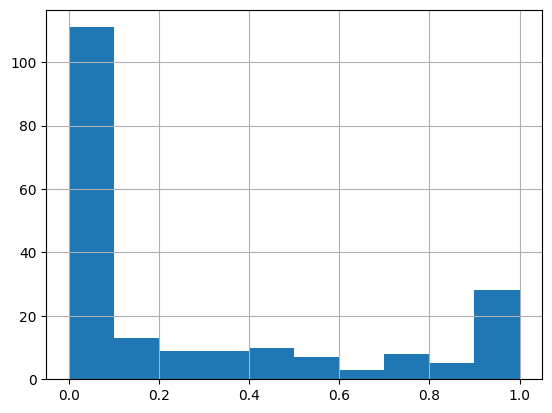

In [31]:
ol4['prop_setor'].hist()

Como a distribuição apresenta muitos valores abaixo de 0.1, vamos analisar esses casos visualmente para confirmar que fazem sentido.

In [32]:
filtro_intersecoes_pequenas = ol4['prop_setor']<=0.1
setores_02 = ol4.loc[filtro_intersecoes_pequenas, 'CD_SETOR'].tolist()
areas_risco_02 = ol4.loc[filtro_intersecoes_pequenas, 'id'].tolist()

In [33]:
# Criar o mapa com as camadas
m = df_censo[df_censo['CD_SETOR'].isin(setores_02)].explore(name='Setor Censitário')

m = df_geo[df_geo['id'].isin(areas_risco_02)].explore(
    m=m, color='orange', name='Área de Risco')

filtered_ol3 = ol4.loc[filtro_intersecoes_pequenas, ['id', 'CD_SETOR', 'geometry', 'prop_setor']]
m = filtered_ol3.explore(m=m, color='purple', name='Interseção')

LayerControl().add_to(m)

# Adicionar a legenda personalizada
legend_html = """
<div style="position: fixed; 
            bottom: 50px; left: 50px; width: 200px; height: 120px; 
            background-color: white; z-index:1000; padding: 10px; 
            border: 2px solid grey; border-radius: 5px;">
    <h4>Legenda</h4>
    <i style="background: orange; width: 10px; height: 10px; display: inline-block;"></i> Área de Risco<br>
    <i style="background: purple; width: 10px; height: 10px; display: inline-block;"></i> Interseção<br>
    <i style="background: blue; width: 10px; height: 10px; display: inline-block;"></i> Setor Censitário
</div>
"""
m.get_root().html.add_child(Element(legend_html))

m

A inspeção visual mostra que parte das interseções não aparentam ser significativas, mas não causarão distorção relevante no cálculo, devido ao fator de ponderação baixo. Outras, entretanto, aparentam ser significativas, mas se tratam de interseções pequenas em comparação com os setores censitários, ocorrendo principalmente em setores sensitários maiores.

##### Calculando a população

O primeiro passo é calcular a população correspondente a cada interseção.

In [34]:
ol4['pop_estimada'] = ol4['v0001']*ol4['prop_setor']

(
    ol4
    .loc[:, ['id','CD_SETOR','v0001', 'prop_setor', 'pop_estimada']]
    .sort_values('pop_estimada', ascending=False)
)

,id,CD_SETOR,v0001,prop_setor,pop_estimada
35,area_risco_geologico.331,355030830000390,801,0.894830,716.758684
38,area_risco_geologico.331,355030830000391,664,0.932883,619.434515
21,area_risco_geologico.260,355030830000259,705,0.798074,562.641987
39,area_risco_geologico.270,355030830000395,549,0.984930,540.726507
103,area_risco_geologico.331,355030830001214,617,0.836013,515.820159
...,...,...,...,...,...
171,area_risco_geologico.281,355030830001503,0,0.019491,0.000000
192,area_risco_geologico.331,355030830001598,0,0.137533,0.000000
200,area_risco_geologico.272,355030830001674,0,0.072576,0.000000
201,area_risco_geologico.329,355030830001683,0,0.000977,0.000000


Depois, calculamos a população agregada por área de risco.

In [35]:
area_risco_pop = (
    ol4
    .loc[:, ['id', 'pop_estimada']]
    .groupby('id')
    .sum()
    .round(0)
    .reset_index()
)

area_risco_pop['pop_estimada'] = area_risco_pop['pop_estimada'].astype(int)
area_risco_pop

,id,pop_estimada
0,area_risco_geologico.260,579
1,area_risco_geologico.261,553
2,area_risco_geologico.263,53
3,area_risco_geologico.270,1579
4,area_risco_geologico.271,539
5,area_risco_geologico.272,127
6,area_risco_geologico.273,307
7,area_risco_geologico.274,55
8,area_risco_geologico.275,129
9,area_risco_geologico.276,118


Finalmente, trazemos a coluna de população para o dataframe original.

In [36]:
df_geo_pop = df_geo.merge(
    area_risco_pop,
    how='inner'
)

df_geo_pop.head()

,id,cd_identificador,nm_area_risco,tx_grau_de_risco_geologico,sg_area_risco,sg_setor_risco,tx_tipo_processo_geologico,cd_tipo_processo_geologico,cd_grau_risco_geologico,dt_atualizacao,dt_vistoria,sg_fonte_original,qt_moradia,geometry,pop_estimada
0,area_risco_geologico.260,260,PARQUE SAO JOSE,AREA ENCERRADA,CS-06,AREA ENCERRADA,ESCORREGAMENTO,2,99,2026-10-06 03:00:00+00:00,2021-09-17,18,0,"POLYGON ((327461.667 7373432.183, 327462.06 73...",579
1,area_risco_geologico.261,261,PARQUE SAO JOSE II,AREA ENCERRADA,CS-07,AREA ENCERRADA,ESCORREGAMENTO,2,99,2026-10-06 03:00:00+00:00,2021-09-27,18,0,"POLYGON ((326971.339 7373085.231, 326973.38 73...",553
2,area_risco_geologico.263,263,JD. NORONHA II,AREA ENCERRADA,CS-34,AREA ENCERRADA,ESCORREGAMENTO,2,99,2026-10-06 03:00:00+00:00,2022-02-22,18,0,"POLYGON ((329227.101 7370337.94, 329240.04 737...",53
3,area_risco_geologico.270,270,JARDIM VARGINHA I,r2,CS-14,CS-14-02 (R2),ESCORREGAMENTO,2,2,2026-10-06 03:00:00+00:00,2022-02-22,18,550,"POLYGON ((328447.064 7368818.166, 328433.939 7...",1579
4,area_risco_geologico.271,271,JARDIM VARGINHA I,r2,CS-14,CS-14-01 (R2),SOLAPAMENTO,4,2,2026-10-06 03:00:00+00:00,2022-02-22,18,260,"POLYGON ((328201.177 7368543.351, 328213.375 7...",539


##### Visualizando a população

Para visualizar o resultado, vamos criar algumas visualizações. Primeiro, vamos criar dois *treemaps* por tipo de processo e grau de risco, alterando a ordem da hierarquia.

In [37]:
df_tree = (
    df_geo_pop
    .groupby(['tx_tipo_processo_geologico', 'tx_grau_de_risco_geologico'], as_index=False)
    ['pop_estimada']
    .sum()
)

df_tree

,tx_tipo_processo_geologico,tx_grau_de_risco_geologico,pop_estimada
0,ESCORREGAMENTO,AREA ENCERRADA,1185
1,ESCORREGAMENTO,r1,2339
2,ESCORREGAMENTO,r2,10397
3,ESCORREGAMENTO,r3,756
4,ESCORREGAMENTO,r4,143
5,ESCORREGAMENTO/SOLAPAMENTO,r1,233
6,ESCORREGAMENTO/SOLAPAMENTO,r2,330
7,ESCORREGAMENTO/SOLAPAMENTO,r4,26
8,SOLAPAMENTO,r2,1361
9,SOLAPAMENTO,r3,448


In [38]:
# Criar o gráfico do tipo treeview
fig = px.treemap(
    df_tree,
    path=['tx_grau_de_risco_geologico', 'tx_tipo_processo_geologico'],  # Caminho hierárquico
    values='pop_estimada',               # Valores para o tamanho das caixas
    title='Somatório de População Estimada por Tipo de Processo Geológico'
)

# Exibir o gráfico
fig.show()

In [39]:
# Criar o gráfico do tipo treeview
fig = px.treemap(
    df_tree,
    path=['tx_tipo_processo_geologico', 'tx_grau_de_risco_geologico'],  # Caminho hierárquico
    values='pop_estimada',               # Valores para o tamanho das caixas
    title='Somatório de População Estimada por Tipo de Processo Geológico'
)

# Exibir o gráfico
fig.show()

Por último, vamos criar um mapa coroplético das áreas de risco, adicionando as camadas de setores censitários envolvidos, interseções envolvidas (e população atribuida) e adicionar também uma camada de satelite.

In [40]:

# Filtrar os setores censitários presentes em ol3
setores_presentes = df_censo[df_censo['CD_SETOR'].isin(ol4['CD_SETOR'].unique())]
# Adicionar os setores censitários ao mapa com apenas o contorno
m = setores_presentes.explore(
    color=None,  # Remove o preenchimento
    style_kwds={'fill': False, 'color': 'skyblue'},  # Define apenas o contorno azul
    name='Setores Censitários',
    tiles='CartoDB positron'  # Mapa base
)

# Criar o mapa base
m = df_geo_pop.explore(
    m=m,
    column='pop_estimada',  # Coluna para o mapa coroplético
    cmap='YlOrRd',          # Paleta de cores
    legend=True,            # Adicionar legenda
    legend_kwds={
        'caption': 'População total',
        'position': 'bottomright',  # Alterar posição da legenda
        'frameon': True             # Adicionar quadro de fundo
    },
    tooltip=['tx_grau_de_risco_geologico', 'tx_tipo_processo_geologico', 'pop_estimada'],  # Informações no tooltip
    name='Áreas de Risco'   # Nome da camada
)

# Adicionar as interseções ao mapa
m = ol4.explore(
    m=m,
    column='pop_estimada',  # Coluna para o mapa coroplético
    cmap='YlOrRd',          # Paleta de cores
    legend=True,            # Adicionar legenda
    legend_kwds={
        'caption': 'População parcial',
        'position': 'bottomright',  # Alterar posição da legenda
        'frameon': True             # Adicionar quadro de fundo
    },
    tooltip=['CD_SETOR', 'pop_estimada'],  # Informações no tooltip
    name='Interseções'      # Nome da camada
)

# Adicionar outra camada base (Google Satellite)
TileLayer(
    tiles='https://mt1.google.com/vt/lyrs=s&x={x}&y={y}&z={z}',
    attr='Google Satellite',
    name='Google Satellite'
).add_to(m)

# Adicionar controle de camadas
LayerControl(position='bottomleft').add_to(m)

# Exibir o mapa
m


In [41]:
makedirs('plots', exist_ok=True)
m.save('plots/população em áreas de risco.html')

# Generalizando o cálculo para toda a cidade

Com base nos passos e na avaliação exposta anterioremente, foram criadas algumas funções no módulo `core` para generalizar a metodologia. São as funções `areal_weighted_interpolation`, de `core.geo`, e `prepare_tracts` e `prepare_risk_area`, de `core.urbanismo`.

## Preparando os setores censitários

In [42]:
df_censo_ajustado = prepare_tracts(df_tracts=df_censo,
                                   df_vegetation=df_veg,
                                   df_street_blocks=df_quadras,
                                   tracts_id_col='CD_SETOR')
df_censo_ajustado.head()

,CD_SETOR,geometry,SITUACAO,CD_SIT,CD_TIPO,AREA_KM2,CD_REGIAO,NM_REGIAO,CD_UF,NM_UF,...,CD_CONCURB,NM_CONCURB,v0001,v0002,v0003,v0004,v0005,v0006,v0007,adjusted_tract_area
0,355030801000001,"MULTIPOLYGON (((339690.308 7392676.463, 339690...",Urbana,1,0,0.071797,3,Sudeste,35,São Paulo,...,3550308,São Paulo/SP,682,329,329,0,2.4,0.0381,289,53835.196205
1,355030801000002,"MULTIPOLYGON (((339928.608 7392728.179, 339928...",Urbana,1,0,0.071902,3,Sudeste,35,São Paulo,...,3550308,São Paulo/SP,1374,1011,1011,0,2.3,0.0150,599,51627.993801
2,355030801000003,"MULTIPOLYGON (((339976.555 7392432.368, 339977...",Urbana,1,0,0.055681,3,Sudeste,35,São Paulo,...,3550308,São Paulo/SP,557,239,238,1,2.7,0.0927,205,40818.436977
3,355030801000004,"MULTIPOLYGON (((339882.544 7392560.093, 339882...",Urbana,1,0,0.064905,3,Sudeste,35,São Paulo,...,3550308,São Paulo/SP,526,245,245,0,2.4,0.0136,221,50289.761982
4,355030801000005,"MULTIPOLYGON (((339673.647 7392190.559, 339669...",Urbana,1,0,0.086822,3,Sudeste,35,São Paulo,...,3550308,São Paulo/SP,579,258,258,0,2.6,0.0905,221,60598.289433


## Preparando as áreas de risco

## Recorte da data de referência

Para respeitar o mês de referência, vamos filtrar as áreas de risco com base na data de vistoria e existência anterior a agosto. Para reduzir a lista dessa análise, vamos remover primeiro as áreas que já existiam em agosto do ano anterior.

In [43]:
df_hid_novas = df_hid[~df_hid['sg_area_risco_hidrologico'].isin(df_hid_hist['sg_area_risco_hidrologico'])]
df_hid_novas

,id,cd_identificador_risco_hidrologico,nm_area_risco_hidrologico,tx_grau_risco_hidrologico,sg_area_risco_hidrologico,sg_setor_risco_hidrologico,tx_tipo_processo,dt_vistoria,qt_moradia,nm_subprefeitura,nm_bacia_hidrografica,geometry
469,risco_hidrologico.470,470,JD DAMASCENO I,R2,HFB-19,HFB-19-01 (R2),ENCHENTE/INUNDACAO,2025-07-10,120,FREGUESIA-BRASILANDIA,CORREGO CABUCU DE BAIXO,"POLYGON ((326327.237 7405742.577, 326333.907 7..."
530,risco_hidrologico.531,531,VILA ROSA MOLA,R2,HVP-11,HVP-11-01 (R2),ENCHENTE/INUNDACAO/ALAGAMENTO,2025-08-21,40,VILA PRUDENTE,RIBEIRAO DO ORATORIO,"POLYGON ((343262.91 7388408.153, 343269.426 73..."
546,risco_hidrologico.547,547,MORRO DO MACACO,R2,HSB-11,HSB-11-01 (R2),ENCHENTE/INUNDACAO/ALAGAMENTO,2025-08-21,20,SAPOPEMBA,RIO ARICANDUVA,"POLYGON ((346561.682 7388169.453, 346574.123 7..."
547,risco_hidrologico.548,548,LOTEAMENTO PARQUE BANCARIO II,R3,HSB-10,HSB-10-01 (R3),ENCHENTE/INUNDACAO/ALAGAMENTO/ENXURRADA,2025-08-21,130,SAPOPEMBA,RIO ARICANDUVA,"POLYGON ((345876.5 7390078, 345870.5 7390090, ..."
548,risco_hidrologico.549,549,LOTEAMENTO PARQUE BANCARIO I,R3,HSB-09,HSB-09-01 (R3),ENCHENTE/INUNDACAO/ENXURRADA,2025-08-21,10,SAPOPEMBA,RIO ARICANDUVA,"POLYGON ((345493.017 7390461.963, 345497.69 73..."
584,risco_hidrologico.585,585,JARDIM PREVIDENCIA,R2,HIP-20,HIP-20-01 (R2),ALAGAMENTO/ENXURRADA,2025-10-09,8,IPIRANGA,CORREGO MOINHO VELHO,"POLYGON ((335752.385 7387450.036, 335766.566 7..."
600,risco_hidrologico.601,601,VILA SILVIA,R2,HPE-14,HPE-14-01 (R2),ENCHENTE/ALAGAMENTO,2025-10-16,25,PENHA,CORREGO MONGAGUA,"POLYGON ((347011.879 7400713.05, 347020.112 74..."
601,risco_hidrologico.602,602,JARDIM ARTHUR ALVIM,R2,HPE-15,HPE-15-01 (R2),ENCHENTE/INUNDACAO/ALAGAMENTO,2025-12-04,10,PENHA,CORREGO TIQUATIRA-LESTE,"POLYGON ((348064.253 7397421.456, 348068.03 73..."
640,risco_hidrologico.641,641,COCAIA I,R3,HCS-23,HCS-23-01 (R3),ENCHENTE,2025-10-02,40,CAPELA DO SOCORRO,CORREGO REIMBERG COCAIA,"POLYGON ((329041.188 7372892.615, 329034.158 7..."
656,risco_hidrologico.657,657,RECANTO CAMPO BELO (NOVA ERA),R2,HPA-10,HPA-10-01 (R2),ALAGAMENTO/ENCHENTE/INUNDACAO,2026-01-07,40,PARELHEIROS,RIBEIRAO PARELHEIROS,"POLYGON ((323075.6 7367474.607, 323050.134 736..."


Agora, verificamos os as datas das vistorias dessas áreas novas.

In [44]:
df_hid_novas[df_hid_novas['dt_vistoria'] > pd.Timestamp('2026-08-01')]

,id,cd_identificador_risco_hidrologico,nm_area_risco_hidrologico,tx_grau_risco_hidrologico,sg_area_risco_hidrologico,sg_setor_risco_hidrologico,tx_tipo_processo,dt_vistoria,qt_moradia,nm_subprefeitura,nm_bacia_hidrografica,geometry


Nenhuma das áreas de risco hidrológico foi adicionada após agosto deste ano, então seguimos com todas as áreas presentes na base.

In [45]:
df_hid_ajustado = prepare_risk_area(risk_area_gdf=df_hid,
                                    risk_area_id_col='id',
                                    risk_grade_col_prefix='tx_grau',
                                    active_risk_prefix='',
                                    subprefeitura_gdf=df_subs,
                                    subprefeitura_id_col='cd_identificador_subprefeitura',
                                    subprefeitura_additional_cols=['cd_subprefeitura',
                                                                   'nm_subprefeitura'])
df_hid_ajustado

,id_area_subprefeitura,id,cd_identificador_risco_hidrologico,nm_area_risco_hidrologico,tx_grau_risco_hidrologico,sg_area_risco_hidrologico,sg_setor_risco_hidrologico,tx_tipo_processo,dt_vistoria,qt_moradia,nm_subprefeitura_1,nm_bacia_hidrografica,cd_identificador_subprefeitura,cd_subprefeitura,nm_subprefeitura_2,geometry
0,risco_hidrologico.1.subpref.22,risco_hidrologico.1,1,BARTOLOMEU FEIO,R2,HPI-01,HPI-01-01 (R2),ALAGAMENTO,2021-08-24,44,PINHEIROS,CORREGO AGUA ESPRAIADA,22,11,PINHEIROS,"POLYGON ((327417.205 7387324.441, 327405.397 7..."
1,risco_hidrologico.2.subpref.20,risco_hidrologico.2,2,MAURO,R2,HVM-01,HVM-01-01 (R2),ENCHENTE/INUNDACAO,2022-02-01,15,VILA MARIANA,CORREGO UBERABA,20,12,VILA MARIANA,"POLYGON ((332469.137 7386410.852, 332469.228 7..."
2,risco_hidrologico.3.subpref.20,risco_hidrologico.3,3,MAURO,R3,HVM-01,HVM-01-02 (R3),ENCHENTE/INUNDACAO,2022-02-01,57,VILA MARIANA,CORREGO UBERABA,20,12,VILA MARIANA,"POLYGON ((332469.228 7386410.305, 332469.137 7..."
3,risco_hidrologico.4.subpref.20,risco_hidrologico.4,4,NEIDE APARECIDA SOLITO,R2,HVM-02,HVM-02-01 (R2),ALAGAMENTO,2022-02-01,12,VILA MARIANA,CORREGO DO SAPATEIRO,20,12,VILA MARIANA,"POLYGON ((331845.268 7389825.129, 331848.22 73..."
4,risco_hidrologico.5.subpref.20,risco_hidrologico.5,5,ESTEVAM HERNANDES,R2,HVM-03,HVM-03-01 (R2),ENCHENTE/INUNDACAO,2022-02-01,8,VILA MARIANA,CORREGO ACLIMACAO,20,12,VILA MARIANA,"POLYGON ((333377.019 7391165.006, 333389.527 7..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
832,risco_hidrologico.789.subpref.2,risco_hidrologico.789,789,ELISEU TEIXEIRA LEITE - PJ,R3,HPJ-12,HPJ-12-03 (R3),ALAGAMENTO/ENCHENTE/INUNDACAO,2022-05-12,40,PIRITUBA-JARAGUA,CORREGO CABUCU DE BAIXO,2,03,FREGUESIA-BRASILANDIA,"MULTIPOLYGON (((325441.385 7405356, 325438.996..."
833,risco_hidrologico.790.subpref.1,risco_hidrologico.790,790,JARDIM RINCAO II,R3,HPJ-05,HPJ-05-02 (R3),ENCHENTE/INUNDACAO,2025-06-11,30,PIRITUBA-JARAGUA,RIBEIRAO DOS PERUS,1,02,PIRITUBA-JARAGUA,"POLYGON ((323551.922 7406882.099, 323554.559 7..."
834,risco_hidrologico.791.subpref.1,risco_hidrologico.791,791,JARDIM RINCAO II,R2,HPJ-05,HPJ-05-01 (R2),ENCHENTE/INUNDACAO/ALAGAMENTO,2025-06-11,450,PIRITUBA-JARAGUA,RIBEIRAO DOS PERUS,1,02,PIRITUBA-JARAGUA,"POLYGON ((323684.797 7407006.774, 323683.944 7..."
835,risco_hidrologico.792.subpref.1,risco_hidrologico.792,792,TOME DE ALMEIDA E OLIVEIRA,R3,HPJ-19,HPJ-19-01 (R3),ENCHENTE/INUNDACAO/ALAGAMENTO,2025-06-11,40,PIRITUBA-JARAGUA,RIBEIRAO VERDE - REGIAO NORTE,1,02,PIRITUBA-JARAGUA,"POLYGON ((325270.466 7403380.11, 325269.55 740..."


Novamente, repetimos a mesma análise quanto à data de referência para as áreas de risco geológico.

In [46]:
df_geo_novas = df_geo[~df_geo['sg_area_risco'].isin(df_geo_hist['sg_area_risco'])]
df_geo_novas.shape

(58, 14)

Novamente, vamos ver quais dessas novas áreas foram vistoriadas após agosto.

In [47]:
df_geo_pos_agosto = df_geo_novas[df_geo_novas['dt_vistoria'] > pd.Timestamp('2026-08-01')]
df_geo_pos_agosto

,id,cd_identificador,nm_area_risco,tx_grau_de_risco_geologico,sg_area_risco,sg_setor_risco,tx_tipo_processo_geologico,cd_tipo_processo_geologico,cd_grau_risco_geologico,dt_atualizacao,dt_vistoria,sg_fonte_original,qt_moradia,geometry
333,area_risco_geologico.334,334,SITIO MATSUMURA,r3,CS-43,CS-43-01 (R3),ESCORREGAMENTO,2,3,2026-10-06 03:00:00+00:00,2026-08-05,18,80,"POLYGON ((325807.38 7368930.882, 325847.094 73..."
334,area_risco_geologico.335,335,SITIO MATSUMURA,r2,CS-43,CS-43-02 (R2),ESCORREGAMENTO,2,2,2026-10-06 03:00:00+00:00,2026-08-05,18,100,"POLYGON ((325847.094 7368811.862, 325858.918 7..."
876,area_risco_geologico.877,877,JARDIM ESPERANCA II,r4,JT-26,JT-26-01 (R4),ESCORREGAMENTO,2,4,2026-10-06 03:00:00+00:00,2026-09-16,18,15,"POLYGON ((338603.93 7405473.068, 338597.67 740..."
877,area_risco_geologico.878,878,JARDIM ESPERANCA II,r3,JT-26,JT-26-02 (R3),ESCORREGAMENTO,2,3,2026-10-06 03:00:00+00:00,2026-09-16,18,95,"POLYGON ((338579.03 7405506.221, 338574.33 740..."
878,area_risco_geologico.879,879,JARDIM ESPERANCA II,r2,JT-26,JT-26-03 (R2),ESCORREGAMENTO,2,2,2026-10-06 03:00:00+00:00,2026-09-16,18,40,"POLYGON ((338655.359 7405477.851, 338660.735 7..."
1355,area_risco_geologico.1356,1356,JARDIM MARILU,r4,SM-39,SM-39-01 (R4),ESCORREGAMENTO,2,4,2026-10-06 03:00:00+00:00,2026-08-20,18,62,"POLYGON ((354793.78 7389981.395, 354854.039 73..."
1356,area_risco_geologico.1357,1357,JARDIM MARILU,r3,SM-39,SM-39-02 (R3),ESCORREGAMENTO,2,3,2026-10-06 03:00:00+00:00,2026-08-20,18,96,"POLYGON ((354966.827 7389500.733, 354949.559 7..."
1357,area_risco_geologico.1358,1358,JARDIM MARILU,r2,SM-39,SM-39-03 (R2),ESCORREGAMENTO,2,2,2026-10-06 03:00:00+00:00,2026-08-20,18,344,"POLYGON ((354813.727 7389714.424, 354798.912 7..."
1358,area_risco_geologico.1359,1359,JARDIM MARILU,r2,SM-39,SM-39-04 (R2),ESCORREGAMENTO,2,2,2026-10-06 03:00:00+00:00,2026-08-20,18,32,"POLYGON ((354926.06 7389760.983, 354914.996 73..."


Vemos que 9 setores aparecem na tabela acima, pertencentes a três áreas de risco: `CS-43`, `JT-26`, `SM-39`. Analisando os relatórios disponíveis no geosampa em 11/10/2026, também adicionados à pasta `docs`, na raíz do projeto, vemos que as três áreas tratam-se, de fato, de áreas adicionadas após agosto de 2026. Portanto, vamos removê-las da análise.

Vamos checar também se existe alguma área de risco dada como encerrada após agosto deste ano.

In [48]:
df_geo[
    (df_geo['tx_grau_de_risco_geologico'].str.contains('ENCERRADA'))
    &
    (df_geo['dt_vistoria'] > pd.Timestamp('2026-08-01'))]

,id,cd_identificador,nm_area_risco,tx_grau_de_risco_geologico,sg_area_risco,sg_setor_risco,tx_tipo_processo_geologico,cd_tipo_processo_geologico,cd_grau_risco_geologico,dt_atualizacao,dt_vistoria,sg_fonte_original,qt_moradia,geometry


Todas a áreas encerradas receberam vistorias anteriores a agosto deste ano, então podemos removê-las da base sem nenhum risco de ambiguidade.

In [49]:

df_geo_pre_agosto = df_geo[~df_geo['sg_area_risco'].isin(df_geo_pos_agosto['sg_area_risco'])]
df_geo_pre_agosto

,id,cd_identificador,nm_area_risco,tx_grau_de_risco_geologico,sg_area_risco,sg_setor_risco,tx_tipo_processo_geologico,cd_tipo_processo_geologico,cd_grau_risco_geologico,dt_atualizacao,dt_vistoria,sg_fonte_original,qt_moradia,geometry
0,area_risco_geologico.1,1,AVENIDA SANTO AFONSO I,AREA ENCERRADA,AD-01,AREA ENCERRADA,ESCORREGAMENTO,2,99,2026-10-06 03:00:00+00:00,2022-02-02,18,0,"POLYGON ((332306.817 7380115.28, 332246.187 73..."
1,area_risco_geologico.2,2,RUA SAO BENTO XV,r3,AD-04,AD-04-03 (R3),SOLAPAMENTO,4,3,2026-10-06 03:00:00+00:00,2026-04-01,18,50,"POLYGON ((332324.725 7378882.633, 332309.159 7..."
2,area_risco_geologico.3,3,RUA SAO BENTO XV,r3,AD-04,AD-04-01 (R3),SOLAPAMENTO,4,3,2026-10-06 03:00:00+00:00,2026-04-01,18,30,"POLYGON ((332060.389 7379330.535, 332080.779 7..."
3,area_risco_geologico.4,4,RUA SAO BENTO XV,r1,AD-04,AD-04-02 (R1),SOLAPAMENTO,4,1,2026-10-06 03:00:00+00:00,2026-04-01,18,200,"POLYGON ((332309.159 7378872.908, 332286.448 7..."
4,area_risco_geologico.5,5,RUA SAO BENTO XV,r1,AD-04,AD-04-04 (R1),SOLAPAMENTO,4,1,2026-10-06 03:00:00+00:00,2026-04-01,18,250,"POLYGON ((332324.725 7378882.633, 332310.909 7..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1396,area_risco_geologico.1397,1397,MANGUE,r2,VP-02,VP-02-02 (R2),SOLAPAMENTO,4,2,2026-10-06 03:00:00+00:00,2025-10-15,18,50,"POLYGON ((343811.294 7387761.125, 343817.849 7..."
1397,area_risco_geologico.1398,1398,MANGUE,r2,VP-02,VP-02-03 (R2),SOLAPAMENTO,4,2,2026-10-06 03:00:00+00:00,2025-10-15,18,12,"POLYGON ((343678.819 7387672.919, 343709.158 7..."
1398,area_risco_geologico.1399,1399,MANGUE,r1,VP-02,VP-02-04 (R1),SOLAPAMENTO,4,1,2026-10-06 03:00:00+00:00,2025-10-15,18,40,"POLYGON ((343958.827 7387695.264, 343950.855 7..."
1399,area_risco_geologico.1400,1400,ANDRE DA CUNHA FONSECA,r2,VP-03,VP-03-01 (R2),SOLAPAMENTO,4,2,2026-10-06 03:00:00+00:00,2023-10-16,18,150,"POLYGON ((344340.465 7388247.202, 344344.264 7..."


In [50]:
df_geo_ajustado = prepare_risk_area(risk_area_gdf=df_geo_pre_agosto,
                                    risk_area_id_col='id',
                                    risk_grade_col_prefix='tx_grau',
                                    active_risk_prefix='r',
                                    subprefeitura_gdf=df_subs,
                                    subprefeitura_id_col='cd_identificador_subprefeitura',
                                    subprefeitura_additional_cols=['cd_subprefeitura',
                                                                   'nm_subprefeitura'])
df_geo_ajustado

,id_area_subprefeitura,id,cd_identificador,nm_area_risco,tx_grau_de_risco_geologico,sg_area_risco,sg_setor_risco,tx_tipo_processo_geologico,cd_tipo_processo_geologico,cd_grau_risco_geologico,dt_atualizacao,dt_vistoria,sg_fonte_original,qt_moradia,cd_identificador_subprefeitura,cd_subprefeitura,nm_subprefeitura,geometry
0,area_risco_geologico.2.subpref.26,area_risco_geologico.2,2,RUA SAO BENTO XV,r3,AD-04,AD-04-03 (R3),SOLAPAMENTO,4,3,2026-10-06 03:00:00+00:00,2026-04-01,18,50,26,16,CIDADE ADEMAR,"POLYGON ((332309.159 7378872.908, 332299.153 7..."
1,area_risco_geologico.3.subpref.26,area_risco_geologico.3,3,RUA SAO BENTO XV,r3,AD-04,AD-04-01 (R3),SOLAPAMENTO,4,3,2026-10-06 03:00:00+00:00,2026-04-01,18,30,26,16,CIDADE ADEMAR,"POLYGON ((332080.779 7379326.178, 332080.118 7..."
2,area_risco_geologico.4.subpref.26,area_risco_geologico.4,4,RUA SAO BENTO XV,r1,AD-04,AD-04-02 (R1),SOLAPAMENTO,4,1,2026-10-06 03:00:00+00:00,2026-04-01,18,200,26,16,CIDADE ADEMAR,"POLYGON ((332286.448 7378858.165, 332220.497 7..."
3,area_risco_geologico.5.subpref.26,area_risco_geologico.5,5,RUA SAO BENTO XV,r1,AD-04,AD-04-04 (R1),SOLAPAMENTO,4,1,2026-10-06 03:00:00+00:00,2026-04-01,18,250,26,16,CIDADE ADEMAR,"POLYGON ((332310.909 7378903.722, 332301.381 7..."
4,area_risco_geologico.6.subpref.26,area_risco_geologico.6,6,RUA DOS MARIMBAS,r3,AD-05,AD-05-02 (R3),ESCORREGAMENTO,2,3,2026-10-06 03:00:00+00:00,2026-03-03,18,5,26,16,CIDADE ADEMAR,"POLYGON ((333374.129 7378039.388, 333345.907 7..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1400,area_risco_geologico.1397.subpref.18,area_risco_geologico.1397,1397,MANGUE,r2,VP-02,VP-02-02 (R2),SOLAPAMENTO,4,2,2026-10-06 03:00:00+00:00,2025-10-15,18,50,18,29,VILA PRUDENTE,"POLYGON ((343817.849 7387754.569, 343823.031 7..."
1401,area_risco_geologico.1398.subpref.18,area_risco_geologico.1398,1398,MANGUE,r2,VP-02,VP-02-03 (R2),SOLAPAMENTO,4,2,2026-10-06 03:00:00+00:00,2025-10-15,18,12,18,29,VILA PRUDENTE,"POLYGON ((343709.158 7387673.539, 343709.424 7..."
1402,area_risco_geologico.1399.subpref.18,area_risco_geologico.1399,1399,MANGUE,r1,VP-02,VP-02-04 (R1),SOLAPAMENTO,4,1,2026-10-06 03:00:00+00:00,2025-10-15,18,40,18,29,VILA PRUDENTE,"POLYGON ((343950.855 7387693.138, 343938.542 7..."
1403,area_risco_geologico.1400.subpref.18,area_risco_geologico.1400,1400,ANDRE DA CUNHA FONSECA,r2,VP-03,VP-03-01 (R2),SOLAPAMENTO,4,2,2026-10-06 03:00:00+00:00,2023-10-16,18,150,18,29,VILA PRUDENTE,"POLYGON ((344344.264 7388245.208, 344351.524 7..."


## Calculando a população para risco hidrológico

Com os setores censitários ajustados, vamos calcular a população para as áreas de risco hidrológico.

In [51]:
df_hid_ajustado.columns

Index(['id_area_subprefeitura', 'id', 'cd_identificador_risco_hidrologico',
       'nm_area_risco_hidrologico', 'tx_grau_risco_hidrologico',
       'sg_area_risco_hidrologico', 'sg_setor_risco_hidrologico',
       'tx_tipo_processo', 'dt_vistoria', 'qt_moradia', 'nm_subprefeitura_1',
       'nm_bacia_hidrografica', 'cd_identificador_subprefeitura',
       'cd_subprefeitura', 'nm_subprefeitura_2', 'geometry'],
      dtype='object')

In [52]:
df_hid_pop = areal_weighted_interpolation(
    df_censo_ajustado,
    df_hid_ajustado,
    'id_area_subprefeitura',
    'v0001',
    'populacao_estimada'
)

df_hid_pop.head()

,id_area_subprefeitura,id,cd_identificador_risco_hidrologico,nm_area_risco_hidrologico,tx_grau_risco_hidrologico,sg_area_risco_hidrologico,sg_setor_risco_hidrologico,tx_tipo_processo,dt_vistoria,qt_moradia,nm_subprefeitura_1,nm_bacia_hidrografica,cd_identificador_subprefeitura,cd_subprefeitura,nm_subprefeitura_2,geometry,populacao_estimada
0,risco_hidrologico.1.subpref.22,risco_hidrologico.1,1,BARTOLOMEU FEIO,R2,HPI-01,HPI-01-01 (R2),ALAGAMENTO,2021-08-24,44,PINHEIROS,CORREGO AGUA ESPRAIADA,22,11,PINHEIROS,"POLYGON ((327417.205 7387324.441, 327405.397 7...",34
1,risco_hidrologico.2.subpref.20,risco_hidrologico.2,2,MAURO,R2,HVM-01,HVM-01-01 (R2),ENCHENTE/INUNDACAO,2022-02-01,15,VILA MARIANA,CORREGO UBERABA,20,12,VILA MARIANA,"POLYGON ((332469.137 7386410.852, 332469.228 7...",54
2,risco_hidrologico.3.subpref.20,risco_hidrologico.3,3,MAURO,R3,HVM-01,HVM-01-02 (R3),ENCHENTE/INUNDACAO,2022-02-01,57,VILA MARIANA,CORREGO UBERABA,20,12,VILA MARIANA,"POLYGON ((332469.228 7386410.305, 332469.137 7...",197
3,risco_hidrologico.4.subpref.20,risco_hidrologico.4,4,NEIDE APARECIDA SOLITO,R2,HVM-02,HVM-02-01 (R2),ALAGAMENTO,2022-02-01,12,VILA MARIANA,CORREGO DO SAPATEIRO,20,12,VILA MARIANA,"POLYGON ((331845.268 7389825.129, 331848.22 73...",16
4,risco_hidrologico.5.subpref.20,risco_hidrologico.5,5,ESTEVAM HERNANDES,R2,HVM-03,HVM-03-01 (R2),ENCHENTE/INUNDACAO,2022-02-01,8,VILA MARIANA,CORREGO ACLIMACAO,20,12,VILA MARIANA,"POLYGON ((333377.019 7391165.006, 333389.527 7...",8


In [53]:
df_hid_sub = areal_weighted_interpolation(
    df_censo_ajustado,
    df_hid_pop,
    'id_area_subprefeitura',
    'v0002',
    'total_domicilios_estimado'
)

df_hid_sub.head()

,id_area_subprefeitura,id,cd_identificador_risco_hidrologico,nm_area_risco_hidrologico,tx_grau_risco_hidrologico,sg_area_risco_hidrologico,sg_setor_risco_hidrologico,tx_tipo_processo,dt_vistoria,qt_moradia,nm_subprefeitura_1,nm_bacia_hidrografica,cd_identificador_subprefeitura,cd_subprefeitura,nm_subprefeitura_2,geometry,populacao_estimada,total_domicilios_estimado
0,risco_hidrologico.1.subpref.22,risco_hidrologico.1,1,BARTOLOMEU FEIO,R2,HPI-01,HPI-01-01 (R2),ALAGAMENTO,2021-08-24,44,PINHEIROS,CORREGO AGUA ESPRAIADA,22,11,PINHEIROS,"POLYGON ((327417.205 7387324.441, 327405.397 7...",34,15
1,risco_hidrologico.2.subpref.20,risco_hidrologico.2,2,MAURO,R2,HVM-01,HVM-01-01 (R2),ENCHENTE/INUNDACAO,2022-02-01,15,VILA MARIANA,CORREGO UBERABA,20,12,VILA MARIANA,"POLYGON ((332469.137 7386410.852, 332469.228 7...",54,20
2,risco_hidrologico.3.subpref.20,risco_hidrologico.3,3,MAURO,R3,HVM-01,HVM-01-02 (R3),ENCHENTE/INUNDACAO,2022-02-01,57,VILA MARIANA,CORREGO UBERABA,20,12,VILA MARIANA,"POLYGON ((332469.228 7386410.305, 332469.137 7...",197,72
3,risco_hidrologico.4.subpref.20,risco_hidrologico.4,4,NEIDE APARECIDA SOLITO,R2,HVM-02,HVM-02-01 (R2),ALAGAMENTO,2022-02-01,12,VILA MARIANA,CORREGO DO SAPATEIRO,20,12,VILA MARIANA,"POLYGON ((331845.268 7389825.129, 331848.22 73...",16,12
4,risco_hidrologico.5.subpref.20,risco_hidrologico.5,5,ESTEVAM HERNANDES,R2,HVM-03,HVM-03-01 (R2),ENCHENTE/INUNDACAO,2022-02-01,8,VILA MARIANA,CORREGO ACLIMACAO,20,12,VILA MARIANA,"POLYGON ((333377.019 7391165.006, 333389.527 7...",8,3


## Calculando a população para risco geológico

Com os setores censitários ajustados, vamos calcular a população para as áreas de risco geológico.

In [54]:
df_geo_ajustado.columns

Index(['id_area_subprefeitura', 'id', 'cd_identificador', 'nm_area_risco',
       'tx_grau_de_risco_geologico', 'sg_area_risco', 'sg_setor_risco',
       'tx_tipo_processo_geologico', 'cd_tipo_processo_geologico',
       'cd_grau_risco_geologico', 'dt_atualizacao', 'dt_vistoria',
       'sg_fonte_original', 'qt_moradia', 'cd_identificador_subprefeitura',
       'cd_subprefeitura', 'nm_subprefeitura', 'geometry'],
      dtype='object')

In [55]:
df_geo_pop = areal_weighted_interpolation(
    df_censo_ajustado,
    df_geo_ajustado,
    'id_area_subprefeitura',
    'v0001',
    'populacao_estimada'
)

df_geo_pop.head()

,id_area_subprefeitura,id,cd_identificador,nm_area_risco,tx_grau_de_risco_geologico,sg_area_risco,sg_setor_risco,tx_tipo_processo_geologico,cd_tipo_processo_geologico,cd_grau_risco_geologico,dt_atualizacao,dt_vistoria,sg_fonte_original,qt_moradia,cd_identificador_subprefeitura,cd_subprefeitura,nm_subprefeitura,geometry,populacao_estimada
0,area_risco_geologico.2.subpref.26,area_risco_geologico.2,2,RUA SAO BENTO XV,r3,AD-04,AD-04-03 (R3),SOLAPAMENTO,4,3,2026-10-06 03:00:00+00:00,2026-04-01,18,50,26,16,CIDADE ADEMAR,"POLYGON ((332309.159 7378872.908, 332299.153 7...",219
1,area_risco_geologico.3.subpref.26,area_risco_geologico.3,3,RUA SAO BENTO XV,r3,AD-04,AD-04-01 (R3),SOLAPAMENTO,4,3,2026-10-06 03:00:00+00:00,2026-04-01,18,30,26,16,CIDADE ADEMAR,"POLYGON ((332080.779 7379326.178, 332080.118 7...",68
2,area_risco_geologico.4.subpref.26,area_risco_geologico.4,4,RUA SAO BENTO XV,r1,AD-04,AD-04-02 (R1),SOLAPAMENTO,4,1,2026-10-06 03:00:00+00:00,2026-04-01,18,200,26,16,CIDADE ADEMAR,"POLYGON ((332286.448 7378858.165, 332220.497 7...",790
3,area_risco_geologico.5.subpref.26,area_risco_geologico.5,5,RUA SAO BENTO XV,r1,AD-04,AD-04-04 (R1),SOLAPAMENTO,4,1,2026-10-06 03:00:00+00:00,2026-04-01,18,250,26,16,CIDADE ADEMAR,"POLYGON ((332310.909 7378903.722, 332301.381 7...",540
4,area_risco_geologico.6.subpref.26,area_risco_geologico.6,6,RUA DOS MARIMBAS,r3,AD-05,AD-05-02 (R3),ESCORREGAMENTO,2,3,2026-10-06 03:00:00+00:00,2026-03-03,18,5,26,16,CIDADE ADEMAR,"POLYGON ((333374.129 7378039.388, 333345.907 7...",1


In [56]:
df_geo_sub = areal_weighted_interpolation(
    df_censo_ajustado,
    df_geo_pop,
    'id_area_subprefeitura',
    'v0002',
    'total_domicilios_estimado'
)

df_geo_sub.head()

,id_area_subprefeitura,id,cd_identificador,nm_area_risco,tx_grau_de_risco_geologico,sg_area_risco,sg_setor_risco,tx_tipo_processo_geologico,cd_tipo_processo_geologico,cd_grau_risco_geologico,dt_atualizacao,dt_vistoria,sg_fonte_original,qt_moradia,cd_identificador_subprefeitura,cd_subprefeitura,nm_subprefeitura,geometry,populacao_estimada,total_domicilios_estimado
0,area_risco_geologico.2.subpref.26,area_risco_geologico.2,2,RUA SAO BENTO XV,r3,AD-04,AD-04-03 (R3),SOLAPAMENTO,4,3,2026-10-06 03:00:00+00:00,2026-04-01,18,50,26,16,CIDADE ADEMAR,"POLYGON ((332309.159 7378872.908, 332299.153 7...",219,91
1,area_risco_geologico.3.subpref.26,area_risco_geologico.3,3,RUA SAO BENTO XV,r3,AD-04,AD-04-01 (R3),SOLAPAMENTO,4,3,2026-10-06 03:00:00+00:00,2026-04-01,18,30,26,16,CIDADE ADEMAR,"POLYGON ((332080.779 7379326.178, 332080.118 7...",68,27
2,area_risco_geologico.4.subpref.26,area_risco_geologico.4,4,RUA SAO BENTO XV,r1,AD-04,AD-04-02 (R1),SOLAPAMENTO,4,1,2026-10-06 03:00:00+00:00,2026-04-01,18,200,26,16,CIDADE ADEMAR,"POLYGON ((332286.448 7378858.165, 332220.497 7...",790,328
3,area_risco_geologico.5.subpref.26,area_risco_geologico.5,5,RUA SAO BENTO XV,r1,AD-04,AD-04-04 (R1),SOLAPAMENTO,4,1,2026-10-06 03:00:00+00:00,2026-04-01,18,250,26,16,CIDADE ADEMAR,"POLYGON ((332310.909 7378903.722, 332301.381 7...",540,224
4,area_risco_geologico.6.subpref.26,area_risco_geologico.6,6,RUA DOS MARIMBAS,r3,AD-05,AD-05-02 (R3),ESCORREGAMENTO,2,3,2026-10-06 03:00:00+00:00,2026-03-03,18,5,26,16,CIDADE ADEMAR,"POLYGON ((333374.129 7378039.388, 333345.907 7...",1,0


# Agrupando os valores por área de risco e subprefeitura

## Agrupando os valores por área de risco

In [57]:
id_col = 'id'
var_cols = ['populacao_estimada','total_domicilios_estimado']

df_geo_agg = (
    df_geo_sub
    .loc[:, [id_col] + var_cols]
    .groupby(id_col)
    .sum()
    .reset_index()
    .merge(df_geo)
)

df_geo_final = df_geo.merge(df_geo_agg, how='left')
df_geo_final = df_geo_final[df_geo_final['id'].isin(df_geo_ajustado['id'].unique())]
df_geo_final

,id,cd_identificador,nm_area_risco,tx_grau_de_risco_geologico,sg_area_risco,sg_setor_risco,tx_tipo_processo_geologico,cd_tipo_processo_geologico,cd_grau_risco_geologico,dt_atualizacao,dt_vistoria,sg_fonte_original,qt_moradia,geometry,populacao_estimada,total_domicilios_estimado
1,area_risco_geologico.2,2,RUA SAO BENTO XV,r3,AD-04,AD-04-03 (R3),SOLAPAMENTO,4,3,2026-10-06 03:00:00+00:00,2026-04-01,18,50,"POLYGON ((332324.725 7378882.633, 332309.159 7...",219.0,91.0
2,area_risco_geologico.3,3,RUA SAO BENTO XV,r3,AD-04,AD-04-01 (R3),SOLAPAMENTO,4,3,2026-10-06 03:00:00+00:00,2026-04-01,18,30,"POLYGON ((332060.389 7379330.535, 332080.779 7...",68.0,27.0
3,area_risco_geologico.4,4,RUA SAO BENTO XV,r1,AD-04,AD-04-02 (R1),SOLAPAMENTO,4,1,2026-10-06 03:00:00+00:00,2026-04-01,18,200,"POLYGON ((332309.159 7378872.908, 332286.448 7...",790.0,328.0
4,area_risco_geologico.5,5,RUA SAO BENTO XV,r1,AD-04,AD-04-04 (R1),SOLAPAMENTO,4,1,2026-10-06 03:00:00+00:00,2026-04-01,18,250,"POLYGON ((332324.725 7378882.633, 332310.909 7...",540.0,224.0
5,area_risco_geologico.6,6,RUA DOS MARIMBAS,r3,AD-05,AD-05-02 (R3),ESCORREGAMENTO,2,3,2026-10-06 03:00:00+00:00,2026-03-03,18,5,"POLYGON ((333358.766 7378074.789, 333374.129 7...",1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1396,area_risco_geologico.1397,1397,MANGUE,r2,VP-02,VP-02-02 (R2),SOLAPAMENTO,4,2,2026-10-06 03:00:00+00:00,2025-10-15,18,50,"POLYGON ((343811.294 7387761.125, 343817.849 7...",79.0,30.0
1397,area_risco_geologico.1398,1398,MANGUE,r2,VP-02,VP-02-03 (R2),SOLAPAMENTO,4,2,2026-10-06 03:00:00+00:00,2025-10-15,18,12,"POLYGON ((343678.819 7387672.919, 343709.158 7...",8.0,4.0
1398,area_risco_geologico.1399,1399,MANGUE,r1,VP-02,VP-02-04 (R1),SOLAPAMENTO,4,1,2026-10-06 03:00:00+00:00,2025-10-15,18,40,"POLYGON ((343958.827 7387695.264, 343950.855 7...",86.0,33.0
1399,area_risco_geologico.1400,1400,ANDRE DA CUNHA FONSECA,r2,VP-03,VP-03-01 (R2),SOLAPAMENTO,4,2,2026-10-06 03:00:00+00:00,2023-10-16,18,150,"POLYGON ((344340.465 7388247.202, 344344.264 7...",229.0,91.0


In [58]:
id_col = 'id'
var_cols = ['populacao_estimada','total_domicilios_estimado']

df_hid_agg = (
    df_hid_sub
    .loc[:, [id_col] + var_cols]
    .groupby(id_col)
    .sum()
    .reset_index()
)

df_hid_final = df_hid.merge(df_hid_agg)
df_hid_final

,id,cd_identificador_risco_hidrologico,nm_area_risco_hidrologico,tx_grau_risco_hidrologico,sg_area_risco_hidrologico,sg_setor_risco_hidrologico,tx_tipo_processo,dt_vistoria,qt_moradia,nm_subprefeitura,nm_bacia_hidrografica,geometry,populacao_estimada,total_domicilios_estimado
0,risco_hidrologico.1,1,BARTOLOMEU FEIO,R2,HPI-01,HPI-01-01 (R2),ALAGAMENTO,2021-08-24,44,PINHEIROS,CORREGO AGUA ESPRAIADA,"POLYGON ((327424.845 7387319.281, 327417.205 7...",34,15
1,risco_hidrologico.2,2,MAURO,R2,HVM-01,HVM-01-01 (R2),ENCHENTE/INUNDACAO,2022-02-01,15,VILA MARIANA,CORREGO UBERABA,"POLYGON ((332457.88 7386410.997, 332469.137 73...",54,20
2,risco_hidrologico.3,3,MAURO,R3,HVM-01,HVM-01-02 (R3),ENCHENTE/INUNDACAO,2022-02-01,57,VILA MARIANA,CORREGO UBERABA,"POLYGON ((332476.102 7386409.838, 332469.228 7...",197,72
3,risco_hidrologico.4,4,NEIDE APARECIDA SOLITO,R2,HVM-02,HVM-02-01 (R2),ALAGAMENTO,2022-02-01,12,VILA MARIANA,CORREGO DO SAPATEIRO,"POLYGON ((331840.472 7389826.482, 331845.268 7...",16,12
4,risco_hidrologico.5,5,ESTEVAM HERNANDES,R2,HVM-03,HVM-03-01 (R2),ENCHENTE/INUNDACAO,2022-02-01,8,VILA MARIANA,CORREGO ACLIMACAO,"POLYGON ((333351.063 7391149.539, 333377.019 7...",8,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
788,risco_hidrologico.789,789,ELISEU TEIXEIRA LEITE - PJ,R3,HPJ-12,HPJ-12-03 (R3),ALAGAMENTO/ENCHENTE/INUNDACAO,2022-05-12,40,PIRITUBA-JARAGUA,CORREGO CABUCU DE BAIXO,"POLYGON ((325473.75 7405366.642, 325472.025 74...",78,34
789,risco_hidrologico.790,790,JARDIM RINCAO II,R3,HPJ-05,HPJ-05-02 (R3),ENCHENTE/INUNDACAO,2025-06-11,30,PIRITUBA-JARAGUA,RIBEIRAO DOS PERUS,"POLYGON ((323562.04 7406876.66, 323551.922 740...",118,41
790,risco_hidrologico.791,791,JARDIM RINCAO II,R2,HPJ-05,HPJ-05-01 (R2),ENCHENTE/INUNDACAO/ALAGAMENTO,2025-06-11,450,PIRITUBA-JARAGUA,RIBEIRAO DOS PERUS,"POLYGON ((323684.858 7407010.34, 323684.797 74...",872,300
791,risco_hidrologico.792,792,TOME DE ALMEIDA E OLIVEIRA,R3,HPJ-19,HPJ-19-01 (R3),ENCHENTE/INUNDACAO/ALAGAMENTO,2025-06-11,40,PIRITUBA-JARAGUA,RIBEIRAO VERDE - REGIAO NORTE,"POLYGON ((325248.523 7403385.87, 325270.466 74...",95,40


## Agrupando os valores por subprefeitura

In [59]:
id_col = 'cd_identificador_subprefeitura'
var_cols = ['populacao_estimada','total_domicilios_estimado']
geo_var_cols = {'populacao_estimada': 'populacao_em_risco_geologico',
                'total_domicilios_estimado': 'domicilios_em_risco_geologico'}
hid_var_cols = {'populacao_estimada': 'populacao_em_risco_hidrologico',
                'total_domicilios_estimado': 'domicilios_em_risco_hidrologico'}

In [60]:
df_hid_sub_agg = (
    df_hid_sub
    .loc[:, [id_col] + var_cols]
    .groupby(id_col)
    .sum()
    .reset_index()
    .rename(columns=hid_var_cols)
)

df_hid_sub_agg

,cd_identificador_subprefeitura,populacao_em_risco_hidrologico,domicilios_em_risco_hidrologico
0,1,5330,2015
1,2,4127,1534
2,3,4913,1767
3,5,4038,1585
4,6,2868,1061
5,7,4745,1866
6,8,3738,1436
7,9,39800,14813
8,10,7494,2676
9,11,6685,2401


In [61]:
df_geo_sub_agg = (
    df_geo_sub
    .loc[:, [id_col] + var_cols]
    .groupby(id_col)
    .sum()
    .reset_index()
    .rename(columns=geo_var_cols)
)

df_geo_sub_agg

,cd_identificador_subprefeitura,populacao_em_risco_geologico,domicilios_em_risco_geologico
0,1,23843,9168
1,2,25376,9433
2,3,9436,3518
3,4,147,56
4,5,19826,7514
5,6,2813,988
6,7,7190,2668
7,8,2760,1043
8,9,2603,931
9,10,10669,3785


In [62]:
df_subs_final = (
    df_subs
    .merge(df_hid_sub_agg, how='left')
    .merge(df_geo_sub_agg, how='left')
    .fillna(0)
)

df_subs_final

,id,cd_identificador_subprefeitura,cd_subprefeitura,nm_subprefeitura,tx_escala,sg_fonte_original,dt_criacao,cd_tipo_discrepancia,dt_atualizacao,cd_usuario_atualizacao,...,qt_area_metro,cd_regiao_05,nm_regiao_05,cd_regiao_08,nm_regiao_08,geometry,populacao_em_risco_hidrologico,domicilios_em_risco_hidrologico,populacao_em_risco_geologico,domicilios_em_risco_geologico
0,subprefeitura.1,1,02,PIRITUBA-JARAGUA,1:5000,GEOGSG,2023-11-30,100200300,2026-03-20 16:14:01.387000+00:00,,...,5.502102e+07,3,Norte,4,Norte 2,"POLYGON ((318663.925 7404127.712, 318663.251 7...",5330.0,2015.0,23843.0,9168.0
1,subprefeitura.2,2,03,FREGUESIA-BRASILANDIA,1:5000,GEOGSG,2023-11-30,100200300,2026-03-20 16:14:01.389000+00:00,,...,3.198020e+07,3,Norte,4,Norte 2,"POLYGON ((327340.628 7399133.313, 327331.514 7...",4127.0,1534.0,25376.0,9433.0
2,subprefeitura.3,3,04,CASA VERDE-LIMAO-CACHOEIRINHA,1:5000,GEOGSG,2023-11-30,100200300,2026-03-20 16:14:01.362000+00:00,,...,2.723234e+07,3,Norte,4,Norte 2,"POLYGON ((329084.795 7402363.669, 329086.123 7...",4913.0,1767.0,9436.0,3518.0
3,subprefeitura.4,4,05,SANTANA-TUCURUVI,1:5000,GEOGSG,2023-11-30,100200300,2026-03-20 16:14:01.395000+00:00,,...,3.578252e+07,3,Norte,5,Norte 1,"POLYGON ((334076.366 7398045.594, 334074.986 7...",0.0,0.0,147.0,56.0
4,subprefeitura.5,5,06,JACANA-TREMEMBE,1:5000,GEOGSG,2023-11-30,100200300,2026-03-20 16:14:01.360000+00:00,,...,6.511566e+07,3,Norte,5,Norte 1,"POLYGON ((335167.648 7404409.048, 335167.247 7...",4038.0,1585.0,19826.0,7514.0
5,subprefeitura.6,6,07,VILA MARIA-VILA GUILHERME,1:5000,GEOGSG,2023-11-30,100200300,2026-03-20 16:14:01.396000+00:00,,...,2.689922e+07,3,Norte,5,Norte 1,"POLYGON ((336762.078 7401144.267, 336794.867 7...",2868.0,1061.0,2813.0,988.0
6,subprefeitura.7,7,21,PENHA,1:5000,GEOGSG,2023-11-30,100200300,2026-03-20 16:14:01.391000+00:00,,...,4.042924e+07,2,Leste,2,Leste 1,"POLYGON ((346801.065 7402842.892, 346800.103 7...",4745.0,1866.0,7190.0,2668.0
7,subprefeitura.8,8,22,ERMELINO MATARAZZO,1:5000,GEOGSG,2023-11-30,100200300,2026-03-20 16:14:01.398000+00:00,,...,1.596639e+07,2,Leste,3,Leste 2,"POLYGON ((349116.316 7399473.221, 349133.905 7...",3738.0,1436.0,2760.0,1043.0
8,subprefeitura.9,9,23,SAO MIGUEL,1:5000,GEOGSG,2023-11-30,100200300,2026-03-20 16:14:01.358000+00:00,,...,2.615923e+07,2,Leste,3,Leste 2,"POLYGON ((352480.323 7397515.871, 352477.052 7...",39800.0,14813.0,2603.0,931.0
9,subprefeitura.10,10,24,ITAIM PAULISTA,1:5000,GEOGSG,2023-11-30,100200300,2026-03-20 16:14:01.366000+00:00,,...,2.160382e+07,2,Leste,3,Leste 2,"POLYGON ((356423.064 7397223.44, 356418.471 73...",7494.0,2676.0,10669.0,3785.0


## Adicionando dados de subprefeitura às áreas de risco geológico

Para que os polígonos possam ser filtrados no Qlik Sense, eles precisam ser possuir uma coluna com o nome das subprefeituras com as quais eles possuem interseção. Porém, apesar de não existir uma camada de subprefeitura na tabela de áreas de risco, a sigla da área de risco geológico já contém a sigla da subprefeitura. Portanto, vamos criar uma coluna com o nome da subprefeitura a partir da sigla da área de risco geológico.

In [63]:
df_geo_final['sg_subprefeitura'] = df_geo_final['sg_area_risco'].str[:2]
df_geo_final

,id,cd_identificador,nm_area_risco,tx_grau_de_risco_geologico,sg_area_risco,sg_setor_risco,tx_tipo_processo_geologico,cd_tipo_processo_geologico,cd_grau_risco_geologico,dt_atualizacao,dt_vistoria,sg_fonte_original,qt_moradia,geometry,populacao_estimada,total_domicilios_estimado,sg_subprefeitura
1,area_risco_geologico.2,2,RUA SAO BENTO XV,r3,AD-04,AD-04-03 (R3),SOLAPAMENTO,4,3,2026-10-06 03:00:00+00:00,2026-04-01,18,50,"POLYGON ((332324.725 7378882.633, 332309.159 7...",219.0,91.0,AD
2,area_risco_geologico.3,3,RUA SAO BENTO XV,r3,AD-04,AD-04-01 (R3),SOLAPAMENTO,4,3,2026-10-06 03:00:00+00:00,2026-04-01,18,30,"POLYGON ((332060.389 7379330.535, 332080.779 7...",68.0,27.0,AD
3,area_risco_geologico.4,4,RUA SAO BENTO XV,r1,AD-04,AD-04-02 (R1),SOLAPAMENTO,4,1,2026-10-06 03:00:00+00:00,2026-04-01,18,200,"POLYGON ((332309.159 7378872.908, 332286.448 7...",790.0,328.0,AD
4,area_risco_geologico.5,5,RUA SAO BENTO XV,r1,AD-04,AD-04-04 (R1),SOLAPAMENTO,4,1,2026-10-06 03:00:00+00:00,2026-04-01,18,250,"POLYGON ((332324.725 7378882.633, 332310.909 7...",540.0,224.0,AD
5,area_risco_geologico.6,6,RUA DOS MARIMBAS,r3,AD-05,AD-05-02 (R3),ESCORREGAMENTO,2,3,2026-10-06 03:00:00+00:00,2026-03-03,18,5,"POLYGON ((333358.766 7378074.789, 333374.129 7...",1.0,0.0,AD
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1396,area_risco_geologico.1397,1397,MANGUE,r2,VP-02,VP-02-02 (R2),SOLAPAMENTO,4,2,2026-10-06 03:00:00+00:00,2025-10-15,18,50,"POLYGON ((343811.294 7387761.125, 343817.849 7...",79.0,30.0,VP
1397,area_risco_geologico.1398,1398,MANGUE,r2,VP-02,VP-02-03 (R2),SOLAPAMENTO,4,2,2026-10-06 03:00:00+00:00,2025-10-15,18,12,"POLYGON ((343678.819 7387672.919, 343709.158 7...",8.0,4.0,VP
1398,area_risco_geologico.1399,1399,MANGUE,r1,VP-02,VP-02-04 (R1),SOLAPAMENTO,4,1,2026-10-06 03:00:00+00:00,2025-10-15,18,40,"POLYGON ((343958.827 7387695.264, 343950.855 7...",86.0,33.0,VP
1399,area_risco_geologico.1400,1400,ANDRE DA CUNHA FONSECA,r2,VP-03,VP-03-01 (R2),SOLAPAMENTO,4,2,2026-10-06 03:00:00+00:00,2023-10-16,18,150,"POLYGON ((344340.465 7388247.202, 344344.264 7...",229.0,91.0,VP


In [64]:
df_geo_final = (
    df_geo_final
    .merge(
        df_subs[['sg_subprefeitura', 'cd_subprefeitura', 'nm_subprefeitura']],
        on='sg_subprefeitura',
        how='left')
)

df_geo_final

,id,cd_identificador,nm_area_risco,tx_grau_de_risco_geologico,sg_area_risco,sg_setor_risco,tx_tipo_processo_geologico,cd_tipo_processo_geologico,cd_grau_risco_geologico,dt_atualizacao,dt_vistoria,sg_fonte_original,qt_moradia,geometry,populacao_estimada,total_domicilios_estimado,sg_subprefeitura,cd_subprefeitura,nm_subprefeitura
0,area_risco_geologico.2,2,RUA SAO BENTO XV,r3,AD-04,AD-04-03 (R3),SOLAPAMENTO,4,3,2026-10-06 03:00:00+00:00,2026-04-01,18,50,"POLYGON ((332324.725 7378882.633, 332309.159 7...",219.0,91.0,AD,16,CIDADE ADEMAR
1,area_risco_geologico.3,3,RUA SAO BENTO XV,r3,AD-04,AD-04-01 (R3),SOLAPAMENTO,4,3,2026-10-06 03:00:00+00:00,2026-04-01,18,30,"POLYGON ((332060.389 7379330.535, 332080.779 7...",68.0,27.0,AD,16,CIDADE ADEMAR
2,area_risco_geologico.4,4,RUA SAO BENTO XV,r1,AD-04,AD-04-02 (R1),SOLAPAMENTO,4,1,2026-10-06 03:00:00+00:00,2026-04-01,18,200,"POLYGON ((332309.159 7378872.908, 332286.448 7...",790.0,328.0,AD,16,CIDADE ADEMAR
3,area_risco_geologico.5,5,RUA SAO BENTO XV,r1,AD-04,AD-04-04 (R1),SOLAPAMENTO,4,1,2026-10-06 03:00:00+00:00,2026-04-01,18,250,"POLYGON ((332324.725 7378882.633, 332310.909 7...",540.0,224.0,AD,16,CIDADE ADEMAR
4,area_risco_geologico.6,6,RUA DOS MARIMBAS,r3,AD-05,AD-05-02 (R3),ESCORREGAMENTO,2,3,2026-10-06 03:00:00+00:00,2026-03-03,18,5,"POLYGON ((333358.766 7378074.789, 333374.129 7...",1.0,0.0,AD,16,CIDADE ADEMAR
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1342,area_risco_geologico.1397,1397,MANGUE,r2,VP-02,VP-02-02 (R2),SOLAPAMENTO,4,2,2026-10-06 03:00:00+00:00,2025-10-15,18,50,"POLYGON ((343811.294 7387761.125, 343817.849 7...",79.0,30.0,VP,29,VILA PRUDENTE
1343,area_risco_geologico.1398,1398,MANGUE,r2,VP-02,VP-02-03 (R2),SOLAPAMENTO,4,2,2026-10-06 03:00:00+00:00,2025-10-15,18,12,"POLYGON ((343678.819 7387672.919, 343709.158 7...",8.0,4.0,VP,29,VILA PRUDENTE
1344,area_risco_geologico.1399,1399,MANGUE,r1,VP-02,VP-02-04 (R1),SOLAPAMENTO,4,1,2026-10-06 03:00:00+00:00,2025-10-15,18,40,"POLYGON ((343958.827 7387695.264, 343950.855 7...",86.0,33.0,VP,29,VILA PRUDENTE
1345,area_risco_geologico.1400,1400,ANDRE DA CUNHA FONSECA,r2,VP-03,VP-03-01 (R2),SOLAPAMENTO,4,2,2026-10-06 03:00:00+00:00,2023-10-16,18,150,"POLYGON ((344340.465 7388247.202, 344344.264 7...",229.0,91.0,VP,29,VILA PRUDENTE


Vamos conferir se todas as áreas de risco possuem pelo menos uma subprefeitura associada.

In [65]:
df_geo_no_sub = df_geo_final[df_geo_final['nm_subprefeitura'].isna()]
df_geo_no_sub

,id,cd_identificador,nm_area_risco,tx_grau_de_risco_geologico,sg_area_risco,sg_setor_risco,tx_tipo_processo_geologico,cd_tipo_processo_geologico,cd_grau_risco_geologico,dt_atualizacao,dt_vistoria,sg_fonte_original,qt_moradia,geometry,populacao_estimada,total_domicilios_estimado,sg_subprefeitura,cd_subprefeitura,nm_subprefeitura
539,area_risco_geologico.566,566,UTARO KANAI,r2,G-11,G-11-01 (R2),ESCORREGAMENTO,2,2,2026-10-06 03:00:00+00:00,2025-01-29,18,60,"POLYGON ((357328.775 7393211.511, 357369.124 7...",71.0,28.0,G-,NaN,NaN
540,area_risco_geologico.567,567,JARDIM AURORA II,r1,G-02,G-02-02 (R1),ESCORREGAMENTO,2,1,2026-10-06 03:00:00+00:00,2025-06-05,18,40,"POLYGON ((355061.793 7396396.52, 355067.776 73...",46.0,18.0,G-,NaN,NaN
541,area_risco_geologico.568,568,JARDIM AURORA II,r3,G-02,G-02-01 (R3),ESCORREGAMENTO,2,3,2026-10-06 03:00:00+00:00,2025-06-05,18,35,"POLYGON ((355061.793 7396396.52, 355063.891 73...",41.0,16.0,G-,NaN,NaN
542,area_risco_geologico.569,569,JARDIM SAO VICENTE,r2,G-18,G-18-01 (R2),SOLAPAMENTO,4,2,2026-10-06 03:00:00+00:00,2025-06-17,18,7,"POLYGON ((354119.21 7397004.31, 354106.757 739...",27.0,11.0,G-,NaN,NaN
543,area_risco_geologico.570,570,JARDIM SAO VICENTE,r3,G-18,G-18-02 (R3),SOLAPAMENTO,4,3,2026-10-06 03:00:00+00:00,2025-06-17,18,4,"POLYGON ((354123.668 7397161.817, 354122.141 7...",6.0,3.0,G-,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
598,area_risco_geologico.625,625,JARDIM SAO PAULO V,r2,G-14,G-14-01 (R2),ESCORREGAMENTO,2,2,2026-10-06 03:00:00+00:00,2026-05-22,18,15,"POLYGON ((357424.234 7393530.913, 357403.86 73...",39.0,15.0,G-,NaN,NaN
599,area_risco_geologico.626,626,JARDIM SAO PAULO V,r4,G-14,G-14-03 (R4),ESCORREGAMENTO,2,4,2026-10-06 03:00:00+00:00,2026-05-22,18,16,"POLYGON ((357267.224 7393533.605, 357272.26 73...",11.0,4.0,G-,NaN,NaN
600,area_risco_geologico.627,627,JARDIM SAO PAULO V,r3,G-14,G-14-02 (R3),ESCORREGAMENTO,2,3,2026-10-06 03:00:00+00:00,2026-05-22,18,95,"POLYGON ((357113.328 7393537.191, 357117.844 7...",324.0,125.0,G-,NaN,NaN
601,area_risco_geologico.628,628,CACAREMA,r2,G-27,G-27-01 (R2),ESCORREGAMENTO/SOLAPAMENTO,3,2,2026-10-06 03:00:00+00:00,2026-07-16,18,110,"POLYGON ((356451.337 7394168.975, 356539.777 7...",114.0,41.0,G-,NaN,NaN


In [66]:
# Criar o mapa base
m = df_subs.explore(
    tooltip=['sg_subprefeitura', 'nm_subprefeitura'],  # Informações no tooltip
    name='Subprefeituras',  # Nome da camada
    # tiles='CartoDB positron',  # Mapa base - Camada base removida por necessidade de chave de API
    color='blue'  # Cor dos polígonos
)

# Adicionar a camada de df_geo_no_sub
m = df_geo_no_sub.explore(
    m=m,  # Adicionar ao mapa existente
    tooltip=['sg_subprefeitura', 'nm_subprefeitura'],  # Informações no tooltip
    name='Áreas de Risco sem Subprefeitura',  # Nome da camada
    color='red'  # Cor dos polígonos
)

# Exibir o mapa
m

Inspecionando visualmente, vemos que as áreas de risco geológico estão localizadas especificamente na subprefeitura de Guaianases, cuja sigla é GU, mas a sigla da área inicia apenas com G. Portanto, vamos considerar que todas as áreas de risco geológico estão associadas à subprefeitura de Guaianases.

In [67]:
df_geo_final.loc[df_geo_final['nm_subprefeitura'].isna(), 'sg_subprefeitura'] = 'GU'
df_geo_final = df_geo_final.drop(columns=['cd_subprefeitura', 'nm_subprefeitura'])

df_geo_final = (
    df_geo_final
    .merge(
        df_subs[['sg_subprefeitura', 'cd_subprefeitura', 'nm_subprefeitura']],
        on='sg_subprefeitura',
        how='left')
)

df_geo_final

,id,cd_identificador,nm_area_risco,tx_grau_de_risco_geologico,sg_area_risco,sg_setor_risco,tx_tipo_processo_geologico,cd_tipo_processo_geologico,cd_grau_risco_geologico,dt_atualizacao,dt_vistoria,sg_fonte_original,qt_moradia,geometry,populacao_estimada,total_domicilios_estimado,sg_subprefeitura,cd_subprefeitura,nm_subprefeitura
0,area_risco_geologico.2,2,RUA SAO BENTO XV,r3,AD-04,AD-04-03 (R3),SOLAPAMENTO,4,3,2026-10-06 03:00:00+00:00,2026-04-01,18,50,"POLYGON ((332324.725 7378882.633, 332309.159 7...",219.0,91.0,AD,16,CIDADE ADEMAR
1,area_risco_geologico.3,3,RUA SAO BENTO XV,r3,AD-04,AD-04-01 (R3),SOLAPAMENTO,4,3,2026-10-06 03:00:00+00:00,2026-04-01,18,30,"POLYGON ((332060.389 7379330.535, 332080.779 7...",68.0,27.0,AD,16,CIDADE ADEMAR
2,area_risco_geologico.4,4,RUA SAO BENTO XV,r1,AD-04,AD-04-02 (R1),SOLAPAMENTO,4,1,2026-10-06 03:00:00+00:00,2026-04-01,18,200,"POLYGON ((332309.159 7378872.908, 332286.448 7...",790.0,328.0,AD,16,CIDADE ADEMAR
3,area_risco_geologico.5,5,RUA SAO BENTO XV,r1,AD-04,AD-04-04 (R1),SOLAPAMENTO,4,1,2026-10-06 03:00:00+00:00,2026-04-01,18,250,"POLYGON ((332324.725 7378882.633, 332310.909 7...",540.0,224.0,AD,16,CIDADE ADEMAR
4,area_risco_geologico.6,6,RUA DOS MARIMBAS,r3,AD-05,AD-05-02 (R3),ESCORREGAMENTO,2,3,2026-10-06 03:00:00+00:00,2026-03-03,18,5,"POLYGON ((333358.766 7378074.789, 333374.129 7...",1.0,0.0,AD,16,CIDADE ADEMAR
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1342,area_risco_geologico.1397,1397,MANGUE,r2,VP-02,VP-02-02 (R2),SOLAPAMENTO,4,2,2026-10-06 03:00:00+00:00,2025-10-15,18,50,"POLYGON ((343811.294 7387761.125, 343817.849 7...",79.0,30.0,VP,29,VILA PRUDENTE
1343,area_risco_geologico.1398,1398,MANGUE,r2,VP-02,VP-02-03 (R2),SOLAPAMENTO,4,2,2026-10-06 03:00:00+00:00,2025-10-15,18,12,"POLYGON ((343678.819 7387672.919, 343709.158 7...",8.0,4.0,VP,29,VILA PRUDENTE
1344,area_risco_geologico.1399,1399,MANGUE,r1,VP-02,VP-02-04 (R1),SOLAPAMENTO,4,1,2026-10-06 03:00:00+00:00,2025-10-15,18,40,"POLYGON ((343958.827 7387695.264, 343950.855 7...",86.0,33.0,VP,29,VILA PRUDENTE
1345,area_risco_geologico.1400,1400,ANDRE DA CUNHA FONSECA,r2,VP-03,VP-03-01 (R2),SOLAPAMENTO,4,2,2026-10-06 03:00:00+00:00,2023-10-16,18,150,"POLYGON ((344340.465 7388247.202, 344344.264 7...",229.0,91.0,VP,29,VILA PRUDENTE


Vamos conferir novamente se todas as áreas de risco possuem pelo menos uma subprefeitura associada.

In [68]:
df_geo_no_sub = df_geo_final[df_geo_final['nm_subprefeitura'].isna()]
df_geo_no_sub

,id,cd_identificador,nm_area_risco,tx_grau_de_risco_geologico,sg_area_risco,sg_setor_risco,tx_tipo_processo_geologico,cd_tipo_processo_geologico,cd_grau_risco_geologico,dt_atualizacao,dt_vistoria,sg_fonte_original,qt_moradia,geometry,populacao_estimada,total_domicilios_estimado,sg_subprefeitura,cd_subprefeitura,nm_subprefeitura


Como nenhum registro possui valor nulo no nome da subprefeitura, sabemos que todos tem uma subprefeitura associada.

Assim, conseguimos criar uma coluna com o nome da subprefeitura associada a cada área de risco geológico, sem a necessidade de nenhuma alteração nos polígonos ou na quantidade de registros da tabela de riscos geológicos.

In [69]:
df_geo_final['nm_subprefeitura'].sort_values().unique().tolist()

['ARICANDUVA-FORMOSA-CARRAO',
 'BUTANTA',
 'CAMPO LIMPO',
 'CAPELA DO SOCORRO',
 'CASA VERDE-LIMAO-CACHOEIRINHA',
 'CIDADE ADEMAR',
 'CIDADE TIRADENTES',
 'ERMELINO MATARAZZO',
 'FREGUESIA-BRASILANDIA',
 'GUAIANASES',
 'IPIRANGA',
 'ITAIM PAULISTA',
 'ITAQUERA',
 'JABAQUARA',
 'JACANA-TREMEMBE',
 'LAPA',
 'M BOI MIRIM',
 'MOOCA',
 'PARELHEIROS',
 'PENHA',
 'PERUS-ANHANGUERA',
 'PIRITUBA-JARAGUA',
 'SANTANA-TUCURUVI',
 'SANTO AMARO',
 'SAO MATEUS',
 'SAO MIGUEL',
 'SAPOPEMBA',
 'VILA MARIA-VILA GUILHERME',
 'VILA PRUDENTE']

Por último, como tivemos duas subprefeituras com mudança de nome entre os anos de 2024 e 2025, vamos alterá-los para os nomes vigentes em 2024.

In [70]:
subs_geo_map = {'CASA VERDE-LIMAO-CACHOEIRINHA': 'CASA VERDE-CACHOEIRINHA',
                'PERUS-ANHANGUERA': 'PERUS'}

df_geo_final['nm_subprefeitura'] = df_geo_final['nm_subprefeitura'].replace(subs_geo_map)
df_geo_final

,id,cd_identificador,nm_area_risco,tx_grau_de_risco_geologico,sg_area_risco,sg_setor_risco,tx_tipo_processo_geologico,cd_tipo_processo_geologico,cd_grau_risco_geologico,dt_atualizacao,dt_vistoria,sg_fonte_original,qt_moradia,geometry,populacao_estimada,total_domicilios_estimado,sg_subprefeitura,cd_subprefeitura,nm_subprefeitura
0,area_risco_geologico.2,2,RUA SAO BENTO XV,r3,AD-04,AD-04-03 (R3),SOLAPAMENTO,4,3,2026-10-06 03:00:00+00:00,2026-04-01,18,50,"POLYGON ((332324.725 7378882.633, 332309.159 7...",219.0,91.0,AD,16,CIDADE ADEMAR
1,area_risco_geologico.3,3,RUA SAO BENTO XV,r3,AD-04,AD-04-01 (R3),SOLAPAMENTO,4,3,2026-10-06 03:00:00+00:00,2026-04-01,18,30,"POLYGON ((332060.389 7379330.535, 332080.779 7...",68.0,27.0,AD,16,CIDADE ADEMAR
2,area_risco_geologico.4,4,RUA SAO BENTO XV,r1,AD-04,AD-04-02 (R1),SOLAPAMENTO,4,1,2026-10-06 03:00:00+00:00,2026-04-01,18,200,"POLYGON ((332309.159 7378872.908, 332286.448 7...",790.0,328.0,AD,16,CIDADE ADEMAR
3,area_risco_geologico.5,5,RUA SAO BENTO XV,r1,AD-04,AD-04-04 (R1),SOLAPAMENTO,4,1,2026-10-06 03:00:00+00:00,2026-04-01,18,250,"POLYGON ((332324.725 7378882.633, 332310.909 7...",540.0,224.0,AD,16,CIDADE ADEMAR
4,area_risco_geologico.6,6,RUA DOS MARIMBAS,r3,AD-05,AD-05-02 (R3),ESCORREGAMENTO,2,3,2026-10-06 03:00:00+00:00,2026-03-03,18,5,"POLYGON ((333358.766 7378074.789, 333374.129 7...",1.0,0.0,AD,16,CIDADE ADEMAR
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1342,area_risco_geologico.1397,1397,MANGUE,r2,VP-02,VP-02-02 (R2),SOLAPAMENTO,4,2,2026-10-06 03:00:00+00:00,2025-10-15,18,50,"POLYGON ((343811.294 7387761.125, 343817.849 7...",79.0,30.0,VP,29,VILA PRUDENTE
1343,area_risco_geologico.1398,1398,MANGUE,r2,VP-02,VP-02-03 (R2),SOLAPAMENTO,4,2,2026-10-06 03:00:00+00:00,2025-10-15,18,12,"POLYGON ((343678.819 7387672.919, 343709.158 7...",8.0,4.0,VP,29,VILA PRUDENTE
1344,area_risco_geologico.1399,1399,MANGUE,r1,VP-02,VP-02-04 (R1),SOLAPAMENTO,4,1,2026-10-06 03:00:00+00:00,2025-10-15,18,40,"POLYGON ((343958.827 7387695.264, 343950.855 7...",86.0,33.0,VP,29,VILA PRUDENTE
1345,area_risco_geologico.1400,1400,ANDRE DA CUNHA FONSECA,r2,VP-03,VP-03-01 (R2),SOLAPAMENTO,4,2,2026-10-06 03:00:00+00:00,2023-10-16,18,150,"POLYGON ((344340.465 7388247.202, 344344.264 7...",229.0,91.0,VP,29,VILA PRUDENTE


In [71]:
df_geo_final['nm_subprefeitura'].sort_values().unique().tolist()

['ARICANDUVA-FORMOSA-CARRAO',
 'BUTANTA',
 'CAMPO LIMPO',
 'CAPELA DO SOCORRO',
 'CASA VERDE-CACHOEIRINHA',
 'CIDADE ADEMAR',
 'CIDADE TIRADENTES',
 'ERMELINO MATARAZZO',
 'FREGUESIA-BRASILANDIA',
 'GUAIANASES',
 'IPIRANGA',
 'ITAIM PAULISTA',
 'ITAQUERA',
 'JABAQUARA',
 'JACANA-TREMEMBE',
 'LAPA',
 'M BOI MIRIM',
 'MOOCA',
 'PARELHEIROS',
 'PENHA',
 'PERUS',
 'PIRITUBA-JARAGUA',
 'SANTANA-TUCURUVI',
 'SANTO AMARO',
 'SAO MATEUS',
 'SAO MIGUEL',
 'SAPOPEMBA',
 'VILA MARIA-VILA GUILHERME',
 'VILA PRUDENTE']

# Padronizando os nomes das subprefeituras

As áreas de risco hidrológico possuem uma coluna com o nome da subprefeitura associada, mas os nomes não estão padronizados. Portanto, vamos padronizar os nomes das subprefeituras para que sejam compatíveis com os nomes das subprefeituras do Qlik Sense.

Quase todas as subprefeituras já estão padronizadas, faltando apenas as subprefeituras de São Miguel e Vila Maria/Vila Guilherme.

In [72]:
df_hid_final['nm_subprefeitura'].unique().tolist()

['PINHEIROS',
 'VILA MARIANA',
 'PERUS',
 'CASA VERDE-CACHOEIRINHA',
 'MOOCA',
 'SE',
 'LAPA',
 'JACANA-TREMEMBE',
 'CAMPO LIMPO',
 'CIDADE TIRADENTES',
 'GUAIANASES',
 'ITAQUERA',
 'M BOI MIRIM',
 'VILA MARIA/VILA GUILHERME',
 'SAO MATEUS',
 'CIDADE ADEMAR',
 'ITAIM PAULISTA',
 'SANTO AMARO',
 'ARICANDUVA-FORMOSA-CARRAO',
 'FREGUESIA-BRASILANDIA',
 'JABAQUARA',
 'VILA PRUDENTE',
 'SAPOPEMBA',
 'IPIRANGA',
 'PENHA',
 'CAPELA DO SOCORRO',
 'PARELHEIROS',
 'BUTANTA',
 'SAO MIGUEL PAULISTA',
 'ERMELINO MATARAZZO',
 'PIRITUBA-JARAGUA']

In [73]:
subs_hid_map = {'SAO MIGUEL PAULISTA': 'SAO MIGUEL',
                'VILA MARIA/VILA GUILHERME': 'VILA MARIA-VILA GUILHERME'}

df_hid_final['nm_subprefeitura'] = df_hid_final['nm_subprefeitura'].replace(subs_hid_map)
df_hid_final

,id,cd_identificador_risco_hidrologico,nm_area_risco_hidrologico,tx_grau_risco_hidrologico,sg_area_risco_hidrologico,sg_setor_risco_hidrologico,tx_tipo_processo,dt_vistoria,qt_moradia,nm_subprefeitura,nm_bacia_hidrografica,geometry,populacao_estimada,total_domicilios_estimado
0,risco_hidrologico.1,1,BARTOLOMEU FEIO,R2,HPI-01,HPI-01-01 (R2),ALAGAMENTO,2021-08-24,44,PINHEIROS,CORREGO AGUA ESPRAIADA,"POLYGON ((327424.845 7387319.281, 327417.205 7...",34,15
1,risco_hidrologico.2,2,MAURO,R2,HVM-01,HVM-01-01 (R2),ENCHENTE/INUNDACAO,2022-02-01,15,VILA MARIANA,CORREGO UBERABA,"POLYGON ((332457.88 7386410.997, 332469.137 73...",54,20
2,risco_hidrologico.3,3,MAURO,R3,HVM-01,HVM-01-02 (R3),ENCHENTE/INUNDACAO,2022-02-01,57,VILA MARIANA,CORREGO UBERABA,"POLYGON ((332476.102 7386409.838, 332469.228 7...",197,72
3,risco_hidrologico.4,4,NEIDE APARECIDA SOLITO,R2,HVM-02,HVM-02-01 (R2),ALAGAMENTO,2022-02-01,12,VILA MARIANA,CORREGO DO SAPATEIRO,"POLYGON ((331840.472 7389826.482, 331845.268 7...",16,12
4,risco_hidrologico.5,5,ESTEVAM HERNANDES,R2,HVM-03,HVM-03-01 (R2),ENCHENTE/INUNDACAO,2022-02-01,8,VILA MARIANA,CORREGO ACLIMACAO,"POLYGON ((333351.063 7391149.539, 333377.019 7...",8,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
788,risco_hidrologico.789,789,ELISEU TEIXEIRA LEITE - PJ,R3,HPJ-12,HPJ-12-03 (R3),ALAGAMENTO/ENCHENTE/INUNDACAO,2022-05-12,40,PIRITUBA-JARAGUA,CORREGO CABUCU DE BAIXO,"POLYGON ((325473.75 7405366.642, 325472.025 74...",78,34
789,risco_hidrologico.790,790,JARDIM RINCAO II,R3,HPJ-05,HPJ-05-02 (R3),ENCHENTE/INUNDACAO,2025-06-11,30,PIRITUBA-JARAGUA,RIBEIRAO DOS PERUS,"POLYGON ((323562.04 7406876.66, 323551.922 740...",118,41
790,risco_hidrologico.791,791,JARDIM RINCAO II,R2,HPJ-05,HPJ-05-01 (R2),ENCHENTE/INUNDACAO/ALAGAMENTO,2025-06-11,450,PIRITUBA-JARAGUA,RIBEIRAO DOS PERUS,"POLYGON ((323684.858 7407010.34, 323684.797 74...",872,300
791,risco_hidrologico.792,792,TOME DE ALMEIDA E OLIVEIRA,R3,HPJ-19,HPJ-19-01 (R3),ENCHENTE/INUNDACAO/ALAGAMENTO,2025-06-11,40,PIRITUBA-JARAGUA,RIBEIRAO VERDE - REGIAO NORTE,"POLYGON ((325248.523 7403385.87, 325270.466 74...",95,40


In [74]:
df_hid_final['nm_subprefeitura'].sort_values().unique()

array(['ARICANDUVA-FORMOSA-CARRAO', 'BUTANTA', 'CAMPO LIMPO',
       'CAPELA DO SOCORRO', 'CASA VERDE-CACHOEIRINHA', 'CIDADE ADEMAR',
       'CIDADE TIRADENTES', 'ERMELINO MATARAZZO', 'FREGUESIA-BRASILANDIA',
       'GUAIANASES', 'IPIRANGA', 'ITAIM PAULISTA', 'ITAQUERA',
       'JABAQUARA', 'JACANA-TREMEMBE', 'LAPA', 'M BOI MIRIM', 'MOOCA',
       'PARELHEIROS', 'PENHA', 'PERUS', 'PINHEIROS', 'PIRITUBA-JARAGUA',
       'SANTO AMARO', 'SAO MATEUS', 'SAO MIGUEL', 'SAPOPEMBA', 'SE',
       'VILA MARIA-VILA GUILHERME', 'VILA MARIANA', 'VILA PRUDENTE'],
      dtype=object)

# Exportando os arquivos

Finalmente, salvamos os arquivos com as camadas com os totais de população e domicílios.

In [75]:
output_dir = path.join('data_output', 'urbanismo')
if not path.exists(output_dir):
    makedirs(output_dir)

for c, gdf in [('risco_hidrologico', df_hid_final),
               ('risco_geologico', df_geo_final)]:
    filename=path.join(output_dir, c)
    gdf.to_file(f'{filename}.gpkg', driver='GPKG', layer=c)

In [76]:
filename = 'populacao_risco_subprefeitura'
filepath=path.join(output_dir, filename)
df_subs_final.drop(columns='geometry').to_csv(f'{filepath}.csv',
                                              index=False,
                                              sep=';',
                                              decimal=',',
                                              encoding='latin1')